# Лабораторная работа №3
## Использование библиотеки NumPy


 Все ячейки следует запускать последовательно.


In [11]:
import numpy as np
from scipy.linalg import solve
import matplotlib.pyplot as plt
from io import StringIO

np.set_printoptions(precision=6, suppress=True, linewidth=110)
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11})

## Задача 1. Производство и потребление электроэнергии
### 1. Загрузка исходных данных
Единица измерения: млрд кВт·ч. Строки соответствуют странам, столбцы — годам 1992–2021. Названия стран очищаются от пробелов. Некорректные и отсутствующие числовые значения загружаются как `NaN`.


In [12]:
# Встроенные исходные файлы для автономного выполнения блокнота.
CSV_DATA = {'global-electricity-generation.csv': "Country,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021\n        Algeria,17.199,18.267,18.703,18.09,19.124,19.739,21.448,23.282,23.88952,25.03064,25.99154,27.80964,29.38706,31.9074,33.12352,34.9758,37.83582,36.206,42.9985,48.17578,53.9845,56.3134,60.39972,64.68244,66.75504,71.49546,72.10903,76.685,72.73591277,77.53072719\n        Angola,1.283,1.332,1.342,1.347,1.377,1.331,1.52,1.3,1.40402,1.59074,1.71668,1.93776,2.18608,2.72998,3.24054,3.1488,4.06368,4.60554,5.31724,5.52336,6.03408,7.97606,9.21666,9.30914,10.203511,10.67604,12.83194,15.4,16.6,16.429392\n        Benin,0.023,0.024,0.048,0.029,0.0487,0.0517,0.0597,0.0677,0.07908,0.06216,0.05934,0.07532,0.0762,0.10064,0.142,0.20498,0.21344,0.12038,0.10816,0.09594,0.04612,0.08848,0.22666,0.31056,0.26004,0.3115,0.19028,0.2017,0.22608,0.24109728\n        Botswana,1.088,1.027,1.044,1.047,0.759,0.87,1.026,1.043,0.89018,0.9494,0.84224,0.68056,0.73978,0.81498,0.746,0.578,0.552,0.417,0.50008,0.44932,0.33,0.86868,2.17628,2.79104,2.52984,2.8438,2.97076,3.0469,2.05144,2.18234816\n        Burkina Faso,0.19,0.205,0.206,0.232,0.263,0.282,0.312,0.348,0.318,0.327,0.36492,0.444662,0.472234,0.489468,0.519525,0.58152,0.589033,0.664416,0.6343,0.69348,0.86834,0.98268,1.11808,1.43986,1.5509,1.64602,1.6464,1.72552,1.647133174,1.761209666\n        Burundi,0.106,0.11,0.116,0.119,0.118,0.121,0.111,0.099,0.1,0.116,0.128,0.102,0.092,0.097,0.094,0.118,0.113,0.122,0.1489,0.147,0.15,0.174,0.187,0.18,0.184,0.279,0.268878,0.355946,0.350520748,0.357991644\n        Cabo Verde,0.057,0.066,0.075,0.078,0.083,0.088,0.096,0.11,0.138,0.155,0.171,0.187,0.206,0.222,0.236,0.253,0.27,0.281,0.325,0.346,0.359,0.385,0.408,0.401,0.423,0.459234,0.459059,0.463,0.433796156,0.45688711\n        Cameroon,2.695,2.699,2.738,2.811,2.928,3.095,3.134,3.34,3.44372,3.50198,3.26092,3.63964,4.0596,3.95208,4.38974,5.0498,5.47968,5.57024,5.7036,5.73125,5.3116,6.15693,6.66283,7.69155,6.92157,7.8328,8.28183,8.35484,8.297891475,8.045474929\n        Central African Republic,0.094,0.095,0.099,0.1,0.102,0.104,0.102,0.103,0.105,0.106,0.106,0.107,0.149,0.159,0.166,0.16,0.16,0.159,0.1591,0.1713,0.1744,0.1384,0.1694,0.1694,0.1704,0.1514,0.151,0.15094,0.151,0.151064\n        Chad,0.079,0.081,0.08,0.084,0.085,0.085,0.086,0.086,0.086,0.094,0.101,0.108,0.115,0.121,0.122,0.121,0.141,0.172,0.188,0.19082,0.2299,0.26196,0.27794,0.2819,0.29466,0.29936,0.30664,0.30946,0.294781188,0.312431184\n        Comoros,0.015,0.015,0.015,0.015,0.016,0.016,0.017,0.017,0.019,0.028,0.031,0.033,0.042,0.045,0.048,0.044,0.043,0.041,0.045,0.059,0.058,0.055,0.051,0.052,0.057,0.0864,0.092896,0.102296,0.13,0.13832\n        Congo-Brazzaville,0.424,0.358,0.322,0.35,0.453,0.448,0.341,0.252,0.29294,0.331,0.392,0.39258,0.38998,0.42432,0.44414,0.39968,0.484,0.52346,0.7597,1.25498,1.64732,1.65502,1.68302,2.65874,2.8325,2.84734,2.975348,3.655103,3.83288,4.02026152\n        Congo-Kinshasa,6.011,5.489,5.258,6.114,6.047,4.992,4.68,5.266,5.94182,5.9187,6.05652,6.10458,7.01452,7.32558,7.4638,7.77584,7.45124,7.7549,7.82184,7.81572,7.51856,8.15646,8.74334,8.83928,9.027,9.422095,10.473865,11.080814,11.952925,11.03964133\n        Cote d'Ivoire,1.666,2.123,2.397,2.962,3.127,3.847,3.831,4.627,4.59984,4.6819,5.0631,4.8737,5.1714,5.31188,5.28622,5.27506,5.43616,5.5585,5.62532,5.76334,6.62434,7.20944,7.82182,8.16076,8.94471,10.07241,9.55322,10.02532,10.5748,10.9822272\n        Djibouti,0.169,0.171,0.171,0.173,0.174,0.176,0.176,0.176,0.18,0.179,0.188,0.188,0.202,0.24,0.263,0.304,0.319,0.328,0.356,0.364,0.3675,0.4075,0.0945,0.167632,0.083032,0.055678,0.05552,0.0574,0.054549745,0.058196929\n        Egypt,43.4961,47.7521,50.0701,52.6912,51.7652,55.5322,59.8092,65.1742,74.46166,79.36634,84.81358,90.47044,96.21028,103.16056,109.49924,118.78692,124.2952,131.68096,160.289,157.084,164.398,168.232,175.302,186.317,189.575,196.849384,199.62301,194.609,189.288301,202.2553182\n        Equatorial Guinea,0.018,0.018,0.018,0.019,0.019,0.02,0.021,0.021,0.09484,0.06476,0.11552,0.1268,0.17004,0.2067,0.26592,0.32796,0.45714,0.51448,0.57602,0.65028,0.745,0.957,1.085,1.299,1.398,1.333667,1.354595,1.40149,1.40835,1.41812456\n        Eritrea,--,--,0.151,0.162,0.181,0.1784,0.184962,0.201,0.19746,0.21908,0.24352,0.26044,0.26608,0.27078,0.25298,0.27084,0.2719,0.27942,0.29446,0.3058,0.31614,0.32372,0.3303,0.33788,0.34446,0.4122,0.4303,0.44446,0.424655551,0.452873507\n        Eswatini,0.404,0.404,0.404,0.41,0.41,0.41,0.408,0.41,0.618,0.629,0.649,0.565,0.536,0.596,0.612,0.634,0.6,0.628,0.6369,0.71521,0.739,0.806,0.653,0.551,0.554,0.671953,0.753253,0.714285,0.740284071,0.744794979\n        Ethiopia,1.221,1.435,1.433,1.453,1.536,1.595,1.634,1.627,1.70062,2.03496,2.06774,2.32004,2.56192,2.86928,3.2904,3.54728,3.76508,3.97976,4.98954,6.31658,7.56528,8.66062,9.47192,10.38586,12.46986,13.13605,13.78592,14.2241,14.23484732,14.67815115\n        Gabon,1.027,1.067,1.071,1.181,1.185,1.241,1.275,1.291,1.2767,1.34506,1.4286,1.46482,1.48414,1.513,1.609,1.68,1.778,1.801,1.86486,1.96148,2.07936,2.02282,1.91848,2.04618,2.24568,2.18761,2.16929,2.259598,2.195922097,2.286328839\n        Gambia,0.067,0.069,0.069,0.07,0.071,0.075,0.082,0.091,0.1105,0.127,0.142,0.158,0.174,0.192,0.204,0.217,0.229,0.2301,0.2333,0.2446,0.2541,0.2481,0.2671,0.2821,0.2981,0.3061,0.3131,0.3048353,0.289586675,0.307921822\n        Ghana,6.575,6.249,6.059,6.054,6.585,6.816,4.725,5.828,7.13422,7.73294,7.10748,5.7259,5.87838,6.67646,8.2144,6.75594,8.14932,8.78,9.92274,10.92166,11.72182,12.5269,12.63308,11.17828,11.39404,12.83426,14.37678,16.6991,20.1902,20.9306928\n        Guinea,0.502,0.507,0.509,0.522,0.527,0.62,0.643,0.725,0.743,0.933,0.984,0.865,0.942,0.881,0.843,0.942,0.967,0.9629,0.9199,0.8499,0.7069,0.644,0.696,1.1396,1.61654,1.773953,1.494324,2.061,3.203097677,2.778671928\n        Guinea-Bissau,0.041,0.044,0.046,0.047,0.048,0.05,0.05,0.051,0.03,0.03,0.02,0.02,0.03,0.03,0.03,0.03,0.03,0.03,0.03,0.031,0.032,0.033,0.0333,0.059076,0.07952,0.07991,0.08168,0.082458,0.082458,0.082458\n        Kenya,3.392,3.578492,3.616,4.035,4.218,4.414,4.535,4.314,4.05356,4.59252,4.75162,5.09798,5.45342,5.8623,6.32428,6.5196,6.40744,6.56226,7.22478,7.57486,8.0844,8.67744,8.36198,9.869,9.689,10.713,11.2364,11.4773,11.75,11.83251388\n        Lesotho,0,0,0,0,0,0,0,0.195,0.288,0.285,0.314,0.325,0.297,0.459,0.525,0.554,0.584,0.648,0.694,0.49,0.486,0.515,0.521,0.53319,0.523028,0.539674,0.539674,0.501,0.501,0.50122\n        Liberia,0.282,0.28,0.28,0.28,0.28,0.294,0.3,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.25,0.25,0.25,0.25,0.28,0.28,0.282,0.282,0.291,0.376,0.376,0.322,0.318,0.897,0.920232\n        Libya,15.933,15.98,16.732,16.92,17.202,17.836,12.716,13.522,14.56624,15.14434,16.47914,17.80642,18.98988,21.312,23.269,24.66,28.878,29.182,30.60488,24.43942,32.21892,35.6387,35.46762,35.26082,29.53528,31.28556,32.12122,31.69634,30.09492439,32.02048755\n        Madagascar,0.58,0.581,0.584,0.609,0.664,0.695,0.75,0.777,0.78,0.886,0.866,0.99,1.1,1.111,1.134,1.184,1.232,1.235,1.32945,1.34829,1.70134,1.85574,1.96983,2.05227,2.02413,2.21108,2.27079,2.020047,1.976233,2.093128464\n        Malawi,0.783,0.953,1,1.018,1.017,1.045,1.184,1.157,1.241,1.269,1.332,1.351,1.489,1.52,1.554,1.585,1.73,1.714,1.951,2.009,2.086,2.094259,2.2037,2.204601,2.192726,2.086975,1.635474,1.696378,1.71,1.424462345\n        Mali,0.271,0.292,0.275,0.305,0.326,0.379,0.387,0.392,0.399,0.402,0.404,0.434,0.45,0.782,0.837,0.823,1,1.123,1.70892,1.89117,2.2509,2.27745,2.35022,2.31755,2.77098,3.29292,3.53727,3.31598,3.199162239,3.388220623\n        Mauritania,0.139,0.139,0.143,0.16,0.175,0.189,0.195,0.203,0.229658,0.278,0.501,0.475,0.518,0.499,0.453,0.478,0.547,0.58,0.632,0.83,0.911,0.939,0.983,1.1363,1.21826,1.52088,1.69008,1.818,1.775118844,1.875855218\n        Mauritius,0.875,0.934,0.974,1.06,0.925,1.073,1.115,1.349,1.681222,1.800656,1.841246,1.971006,2.049926,2.145066,2.214026,2.32117,2.43815,2.45839,2.5659,2.59926,2.65092,2.74942,2.79634,2.85704,2.89832,2.97018,2.98177,3.0869,2.7363,2.885610665\n        Morocco,9.184,9.338,10.349,12.066,12.364,13.162,13.393,13.113,12.13114,14.19886,15.16242,16.4867,17.49562,18.72854,19.14016,19.22538,19.50828,19.9071,23.5821,24.9381,27.318,26.7,27.615414,29.499414,30.349,31.4378,34.136028,39.860361,38.217589,41.150914\n        Mozambique,0.408,0.386,0.389,0.402,0.47,0.993,1.512,7.629,9.60436,11.77836,12.61472,10.83478,11.63224,13.19574,14.6298,15.95522,15.02422,16.83722,16.55286,16.7288,15.08184,14.79246,17.5806,19.69688,18.53324,16.7942,16.83459,18.717719,19.34346088,19.90774462\n        Namibia,0,0,0,1.155,0.882,0.634,1.007,1.195,1.398,1.36164,1.44694,1.51016,1.58694,1.67202,1.679,1.593,1.643,1.472,1.29752,1.42344,1.63984,1.33746,1.51222,1.55896,1.46128,1.74404,1.4083,1.36136,1.957,1.56716\n        Niger,0.153,0.149,0.138,0.139,0.143,0.14,0.136,0.142,0.178,0.156,0.172,0.18,0.189,0.219,0.206,0.209,0.212,0.239,0.2726,0.32148,0.38206,0.42066,0.42266,0.50638,0.50274,0.53388,0.53762,0.60342,0.4265,0.450852\n        Nigeria,14.247,13.913,14.877,13.889,14.367,14.697,14.73,15.432,14.144,14.844,20.676,19.358,23.237,22.528,22.049,21.92394,20.14266,18.83012,24.88718,25.72094,27.30318,27.45858,30.6099,30.80597,32.00501,32.78739,31.85828,31.647071,29.73432393,31.45787819\n        Reunion,1.05,1.062,1.074,1.152,1.215,1.41,1.499,1.503,1.941,2.098,2.076,2.165,2.389,2.499,2.534,2.586,2.688,2.779,2.85,2.893,ie,ie,ie,ie,ie,ie,ie,ie,ie,ie\n        Rwanda,0.174,0.157,0.16,0.162,0.144,0.164,0.164,0.131,0.114,0.09125,0.0996875,0.12,0.092,0.113,0.161,0.1592,0.1842,0.2402,0.27482,0.31738,0.3354,0.37748,0.4752,0.5823,0.67266,0.76726,0.860882,1.011711,0.910912,0.8546512\n        Saint Helena,0.005,0.005,0.006,0.006,0.006,0.006,0.006,0.005,0.005,0.005,0.005,0.007,0.008,0.008,0.008,0.008,0.008,0.008,0.008,0.008,0.009,0.009,0.00837916,0.00767604,0.00789224,0.0080793,0.00731038,0.00849666,0.008393,0.008930152\n        Sao Tome and Principe,0.015,0.015,0.018,0.019,0.02,0.021,0.022,0.026,0.028,0.024,0.03,0.031,0.035,0.039,0.04,0.043,0.045,0.049,0.054,0.056,0.061,0.067,0.072,0.078,0.082,0.085,0.087,0.0899,0.0951,0.1005464\n        Senegal,1.004,0.993,1.025,1.071,1.133,1.216,1.279,1.317,1.44,1.689,1.794,1.904,1.995,2.275,2.281,2.46748,2.587,2.65786,2.81858,2.86534,3.16248,3.30144,3.63756,3.88164,4.17114,4.47188,4.66082,5.17598,5.233902475,5.615708528\n        Seychelles,0.103,0.11,0.118,0.121,0.125,0.139,0.149,0.162,0.178,0.18,0.205,0.21,0.212,0.217,0.237,0.255,0.253,0.259,0.283,0.377,0.39,0.409,0.41925,0.435572,0.46631,0.483102,0.48858,0.535894,0.5962,0.6431768\n        Sierra Leone,0.216,0.219,0.223,0.09,0.135,0.09,0.103,0.068,0.089,0.131,0.148,0.135,0.112,0.078,0.039,0.057,0.058,0.06,0.163,0.172,0.173,0.16,0.181844,0.196022,0.209584,0.218866,0.254672,0.207708,0.20681017,0.207889733\n        Somalia,0.249,0.252,0.255,0.256,0.259,0.259,0.26,0.261,0.235,0.245,0.258,0.263,0.263,0.273,0.282,0.292,0.301,0.305,0.307,0.31,0.324,0.334,0.3341,0.3352,0.342,0.3472,0.3472,0.3462,0.3802,0.40788\n        South Africa,157.079,163.268,170.705,176.051,186.188,195.063,191.041,188.49,195.82886,196.28928,203.2381,217.20568,227.5277,227.92804,235.4471,245.56207,239.68607,230.64077,241.98442,243.45328,239.86604,237.53878,235.54795,230.81604,234.47229,236.33738,235.64056,232.99074,220.12096,221.4995447\n        Sudan,1.59,1.639,1.803,1.8,1.993,2.073,2.033,2.338,2.574,2.843,3.092,3.341,3.454,3.803,4.458,4.9408,5.39742,6.415,7.49518,8.39572,9.32998,10.23186,11.26822,12.81638,14.10332,15.2273,15.90455,16.31026,16.47127864,16.59542448\n        Tanzania,1.79,1.847,1.676,1.808,1.959,1.66,2.407,2.346,2.439,2.718,2.82,2.627,2.838,3.43,3.312,4.058,4.256,4.657,5.15612,5.01124,5.4772,5.77572,6.08866,6.5569,6.97612,7.01072,7.22022,7.59084,8.005382814,8.168690514\n        Togo,0.212,0.315,0.242,0.344,0.283,0.19,0.284,0.282,0.17,0.119,0.147,0.172,0.179,0.181,0.209,0.17936,0.1182,0.138,0.16938,0.12158,0.10468,0.09299,0.20252,0.37334,0.43244,0.7703,0.56982,0.70056,0.588150458,0.625065047\n        Tunisia,5.812,5.937,6.314,6.872,7.457,8.004,8.563,9.405,9.964,10.714,11.135,11.676,12.293,12.976,13.281,12.92112,13.50536,14.34644,14.95458,15.33848,16.79978,17.0767,17.8685,18.35076,18.48988,19.17152,19.5234,20.53774,19.57393591,20.92347402\n        Uganda,0.9823,0.9672,1.0065,1.0449,1.1176,1.251,1.266,1.264,1.587,1.583,1.712,1.8,1.937,1.953,1.5705572,1.964,2.314,2.399,2.68961,2.61412,1.9574,2.59183,2.80655,2.86793,3.77268,3.91354,4.31537,4.31865,4.44987172,4.40101286\n        Western Sahara,0.08,0.08,0.08,0.082,0.082,0.082,0.082,0.08,0.08,0.08,0.085,0.085,0.085,0.085,0.09,0.09,0.09,0.09,0,0,0,0,0,0,0,0,0,0,0,0\n        Zambia,7.72,7.721,7.714,7.842,7.091,7.859,7.524,7.684,7.757,7.9,8.107,8.261,8.458,8.886,9.666,9.6042,9.4912,9.862,10.409304,11.447532,12.31092,13.231964,14.358504,13.359864,11.620963,14.434903,16.131655,14.660972,15.105044,17.714251\n        Zimbabwe,8.188,7.359,7.171,7.429,6.991,6.966,6.304,6.813,6.738,7.582,8.263,8.539,9.411,9.035,7.68,7.35,7.387,7.112,8.44068,8.92854,8.92948,9.2557,9.70712,9.38778,6.82494,7.34946,9.187,8.230839,7.594009611,8.030893985\n        Armenia,8.615,6.131,5.494,5.038,5.835,5.656,5.822,5.561,5.61848,5.5676,5.21526,5.21174,5.90414,5.97832,5.61744,5.584465,5.46643,5.37776,6.17572,7.0706,7.62206,7.30562,7.33366,7.39094,6.95114,7.36168,7.38726,7.30447,7.44504,7.32438676\n        Azerbaijan,18.58,18.074,16.609,16.1,16.14,15.912,17.015,17.162,17.6541,17.89592,18.47162,20.13104,20.48172,20.09546,22.32042,20.65402,20.45634,17.85152,17.76022,19.20992,21.69998,22.03526,23.32006,23.30046,23.56828,22.96136,23.82038,24.60663,24.37144,26.299773\n        Belarus,35.34,31.368,29.514,23.424,22.305,24.495,21.991,24.829,24.53656,23.56102,24.86938,25.03106,29.33944,29.1073,29.84608,29.8717,32.90438,28.48172,32.79164,30.25188,28.92924,29.60146,32.63418,32.0097,31.5473,32.45526,36.65996,37.6835,36.2109,43.86748389\n        Georgia,11.144,9.465,8.669,6.646,7.081,7.047,7.903,7.886,7.27116,6.7983,7.1596,7.05696,6.8115,7.14314,7.11568,8.17316,8.30354,8.41524,9.98458,9.97676,9.47468,9.86872,10.16584,10.60526,11.34684,11.30502,11.9221,11.59728,11.16,12.645\n        Kazakhstan,78.557,73.56,63.243,63.176,55.953,49.49,46.604,44.956,48.62142,53.84944,55.28588,60.46554,63.33072,64.16854,67.74666,72.41138,75.88098,74.33214,78.08956,81.78582,87.63838,97.31006,90.01284,86.69606,89.61752,97.599,101.830574,102.471039,98.54476087,104.4782558\n        Kyrgyzstan,11.725,11.051,12.743,12.164,13.545,12.426,11.416,12.975,15.708,14.66164,12.84006,15.3174,16.03792,14.637,14.275,14.577,11.588,10.929,11.92948,14.95586,14.96666,13.85516,14.36256,12.8032,13.04092,15.29334,15.3094,14.84014,16.174,14.461936\n        Moldova,10.586,9.668,7.748,5.72,5.773,4.976,4.617,4.167,5.307,5.636,5.764,5.952,5.799,5.972,6.08,5.883,6.018,6.194,6.111,5.782,5.799,4.508,5.378,6.049,5.852,4.962,5.38824,5.69599,6.181,6.6568\n        Russia,965.246,914.255,807.727,815.158,804.127,793.875,786.491,798.773,832.944,842.446,846.084,868.008,885.454,901.02176,941.65068,960.14694,984.17081,939.5156,982.56224,998.47541,1013.95248,1003.59126,1007.4473,1010.03494,1033.16006,1036.282948,1046.83945,1062.86856,1044.284104,1109.689916\n        Tajikistan,16.609,17.533,16.798,14.612,14.842,13.85,14.265,15.621,13.983,14.229,15.142,16.336,16.319,16.92,16.768,17.323,16.989,15.958,16.2689,16.07372,16.80056,16.94136,15.9904,16.98228,17.03,17.88414,19.47718,20.58658,19.7338,19.72368\n        Turkmenistan,12.392,11.879,9.866,9.212,9.495,8.928,8.852,8.329,9.255,9.974,10.058,10.152,11.205,12.051,12.831,13.98738,14.13778,15.024,15.6634,16.1898,16.688,17.7408,19.179,21.18496,21.18496,21.185114,21.185154,21.185154,20.11469132,21.40182971\n        Ukraine,238.232,217.14,191.715,183.293,173.367,168.342,163.094,161.879,159.885,163.038,163.645,169.977,172.535,175.293,182.323,185.065861,181.58,163.765,178.2679,183.83,187.01548,182.33684,171.37686,152.4034,153.58546,145.66706,150.20788,143.83374,145.02182,150.0395\n        Uzbekistan,48.17,46.568,45.289,44.907,43.02,43.579,43.433,42.866,44.323,44.949,46.661,46.817,47.404,46.974,43.907,44.607,40.2006,44.6008,49.26602,49.92094,50.1503,51.627216,52.722766,54.551956,56.004223,58.06589,59.424857,60.11528,55.94145423,59.20353494\n        Albania,3.31,3.441,3.858,4.359,5.857,5.125,5.01,5.337,4.68336,3.64778,3.64056,5.21758,5.5426,5.3848,5.03842,2.82768,3.8311,5.20187,7.49277,4.14694,4.67865,6.89041,4.67776,5.83705,7.70618,4.48075,8.46748,5.17594,5.313,8.962943\n        Austria,49.492,50.088,50.71,53.733,52.019,54.272,54.62,57.615,57.92042,58.93718,58.4038,55.50484,59.30708,61.30282,59.45448,60.17314,61.97422,63.583,63.937654,58.36573,64.742413,60.802337,57.646226,58.069497,61.732328,63.467831,61.2203869,68.8018868,67.7389039,64.2269678\n        Belgium,67.377,66.105,67.275,69.309,70.833,73.42695,77.33711,78.572,77.99376,74.06752,76.282,78.76056,79.49996,80.61608,79.3191,82.41244,78.76178,84.84878,91.002351,86.160664,79.344337,79.545951,69.431713,66.970488,82.053225,82.77065,71.8065043,89.9204609,85.690887,94.8636857\n        Bosnia and Herzegovina,6.304,3.245,4.162,4.32,7.157,8.471,9.282,10.191,10.0579,10.25858,10.40098,10.8151,12.26306,12.14576,12.80288,11.27702,14.17664,15.04026,16.49812,14.58342,13.44898,16.7691,15.4965,14.97832,16.98653,15.38966,18.20808,16.65445,15.69252,17.36192136\n        Bulgaria,33.704,35.952,36.0665,39.569,41.067,39.854,39.253,35.912,38.3182,40.65336,40.75548,39.52822,38.79962,41.2454,42.68836,40.251732,41.72358,39.63248,43.10972,46.73622,43.6861,40.46622,44.3295,44.079049,40.217008,40.431095,41.5053836,38.7389512,35.6656192,41.5291854\n        Croatia,8.578,9.015,8.026,8.594,10.277,9.353,10.505,11.833,10.22004,11.65016,11.68252,12.02396,12.6961,11.88718,11.81644,11.50088,11.69966,12.23508,14.32912,10.7817,10.15614,13.53568,13.08606,10.742444,12.052593,11.293476,13.125812,12.2922931,12.7997589,14.6034781\n        Cyprus,2.26,2.426,2.52,2.325,2.4365,2.548,2.777,2.951,3.168,3.338,3.558,3.809,3.948,4.114,4.373,4.579,4.775,4.856,5.00806,4.64494,4.4494,4.05522,4.10502,4.316208,4.670173,4.781059,4.8302456,4.916683,4.6534741,4.8776793\n        Czechia,--,55.52935,55.38585,57.48185,60.163,61.16639,61.38,60.394,68.611,69.92992,71.66256,78.0634,78.9831,76.96922,78.5972,82.55662,78.30462,76.93744,77.694447,79.244128,79.668827,78.990421,78.254983,75.785457,75.324978,78.886881,79.9821752,79.1107549,73.9507328,76.6408673\n        Denmark,28.98,32.039,37.903,34.589,50.509,41.852,38.89373,36.856,34.22084,35.83744,37.36228,43.9208,38.60988,34.70892,43.47584,37.62304,35.076,34.851,37.913516,34.616036,30.258867,34.152282,31.85753,28.974012,30.197344,30.919752,30.4186372,29.8828185,28.9196916,32.7931727\n        Estonia,11.121,8.571,8.602,8.172,8.557,8.666,8.011,7.773,8.00054,7.9855,8.09144,9.60974,9.68936,9.59936,9.15588,11.4673,9.95796,8.28482,11.804113,11.743832,10.652741,11.959914,11.180938,9.301154,10.641563,11.501345,11.1889412,6.8665502,5.9161313,6.653181\n        Faroe Islands,0.191,0.173423,0.168605,0.16757,0.17462,0.175673,0.183441,0.192787,0.204017,0.221173,0.230724,0.238492,0.239156,0.235753,0.249856,0.25942,0.264851,0.264517,0.268143,0.264,0.28,0.28,0.297,0.306,0.306,0.324,0.3398,0.371,0.4064,0.4223616\n        Finland,55.507,58.645,62.865,61.299,66.3682,65.52758,67.473,66.683,67.0747,71.23686,71.53498,80.30388,82.06266,67.86486,78.8327,77.9372,74.3593,69.14244,77.72505,70.963659,68.234809,69.05982,66.168692,66.888647,67.011713,65.811381,68.5524094,67.0671163,67.5709779,69.6532502\n        France,437.9738,447.371,452.95,467.8295,483.443,476.755,482.398,494.518,509.63366,519.4517,526.14238,533.6022,540.59828,544.67706,542.97918,538.14118,544.0015,507.40836,539.912655,543.204119,543.056111,552.39671,542.444671,550.247779,536.004261,532.963003,552.9287295,543.7815506,506.0036239,530.4178475\n        Germany,503.627,493.139,495.603,502.972,520.14,517.17443,522.214,519.283,540.11648,549.6969,549.97644,572.726,579.7422,577.6862,594.1134,598.5474,600.122,558.121,592.76104,575.676356,591.388791,601.497317,592.096504,611.510695,616.083534,620.117876,607.5568443,577.612099,545.3611372,557.1440648\n        Gibraltar,0.083,0.083,0.083,0.083,0.085,0.087,0.092,0.096,0.1175,0.11844,0.12126,0.12596,0.12784,0.1363,0.14194,0.1457,0.15604,0.16356,0.16638,0.16074,0.16544,0.17766,0.18612,0.21056,0.20116,0.20022,0.2021,0.20586,0.19545657,0.207965791\n        Greece,35.031,35.861,37.991,38.897,40.026,40.80618,43.546,46.581,50.26192,49.78354,50.6184,54.50368,55.37564,55.95374,56.7105,58.86248,59.09142,57.7506,53.498057,53.668572,53.654754,52.614029,46.636551,47.867296,50.431187,50.513953,50.0798786,45.5072992,42.5123637,52.4739582\n        Hungary,30.026,31.163306,31.743,32.226733,33.22876,33.52012,35.21641,35.724,33.23722,34.38844,34.14072,32.22422,31.86014,33.7422,33.65762,37.74876,37.70684,33.7298,34.960717,33.810596,32.587303,28.273384,27.436954,28.442948,29.89166,31.00248,30.1610501,32.463938,33.177421,34.1914781\n        Iceland,4.503,4.682,4.735,4.933,5.0747,5.53369,6.225,7.128,7.6197,7.96676,8.34564,8.42864,8.55176,8.6157,9.85676,11.89288,16.34288,16.71088,16.746003,16.850998,17.295999,17.999998,17.803,18.558001,18.171608,18.846295,19.4324979,19.119793,18.778694,19.2629881\n        Ireland,14.778,15.13,15.77,16.496,17.711,18.43922,19.567,20.396,22.17072,23.0527,23.24434,23.23862,23.58174,24.00882,25.42254,26.142,28.127,26.296,27.165581,26.372895,26.202849,24.618802,24.904899,27.189981,29.259077,29.879721,29.9323625,29.8700272,30.9904099,33.5958721\n        Italy,211.296,207.754,216.413,223.763,225.575,232.36697,238.669,243.915,253.21828,255.25074,259.79924,264.89276,277.3016,278.1547,288.70848,289.4176,295.01606,272.7457,288.117063,291.006684,287.426111,278.836768,269.699149,273.399218,279.976334,285.629453,280.369202,263.7055922,272.4289509,274.1786604\n        Latvia,3.733,3.832,4.339,3.887,3.029,4.379,4.382,4.001,4.02922,4.16554,3.8596,3.85378,4.56842,4.78348,4.7377,4.62742,5.11928,5.41322,6.080051,5.582804,5.770285,5.852735,4.813333,5.184397,6.033633,7.17202,6.317738,6.052739,5.5190101,5.5384285\n        Lithuania,17.645,13.949,9.162,12.157,14.648,12.912,16.104,12.254,10.34674,13.42376,16.13264,17.4843,17.44288,13.069113,10.84036,12.1015,11.959,13.09984,4.113736,3.46206,3.807551,3.543759,3.064047,3.607144,3.16264,3.109055,2.5445654,2.9224943,4.1760986,3.7041126\n        Luxembourg,0.389,0.433,0.318,0.144,0.107,0.064,0.062,0.093,0.1321,0.56193,2.35157,2.3188,2.88582,2.83858,2.99818,2.7053,2.21288,2.64042,2.715026,2.24385,2.333717,1.459888,1.505688,0.861374,0.306917,0.462601,0.5452682,0.7711928,0.8836639,0.9208151\n        Malta,1.401,1.41,1.449,1.534,1.559,1.585,1.618,1.743,1.80198,1.82642,1.92888,2.10184,2.08304,2.1056,2.12534,2.15824,2.17328,2.03892,1.98822,2.04886,2.16092,2.11904,2.1148,1.241942,0.807333,1.603623,1.9119268,2.0016997,2.0818584,2.1116277\n        Montenegro,--,--,--,--,--,--,--,--,--,--,--,--,--,--,2.86288,2.0794,2.73566,2.69766,3.91868,2.55688,2.74798,3.83454,3.07274,2.90128,3.04912,2.39528,3.304143,2.978541,2.806037,3.298510285\n        Netherlands,72.592,72.388653,75.002,76.11,79.993,80.43608,84.685,80.642,84.31044,88.12854,90.32342,91.17422,96.5419,94.50572,92.93152,99.27836,101.72108,107.35418,116.502576,111.041441,101.080639,99.284698,100.436711,107.602149,111.549436,113.716349,112.2703969,119.0127664,118.4576141,117.439938\n        North Macedonia,5.721,4.896,5.491,5.804,6.286,6.374,6.679,6.521,6.46054,6.01184,5.76296,6.40216,6.3409,6.60282,6.67146,6.15872,5.97474,6.48152,6.94626,6.4255,5.93892,5.80794,5.11708,5.279922,5.29601,5.243679,5.2859148,5.5017894,5.0426645,5.2351137\n        Norway,115.77685,118.335,110.608,120.603,103.516,108.625,114.879,120.87,140.80948,119.70842,128.56782,105.2534,108.66352,135.3932,119.72378,134.10084,139.21964,129.06828,122.150138,125.262082,145.660999,132.633003,140.242,142.176,147.491,147.570003,145.1080429,131.9557672,153.9079342,157.5030781\n        Poland,122.583,123.521,124.925,128.481,132.45722,132.447,132.249,130.904,133.61234,134.23304,133.03392,140.19562,142.7233,145.393158,150.719265,149.063852,145.509356,142.279486,143.35879,149.03546,143.015423,148.036692,142.273714,148.742268,151.980086,154.781107,155.1287839,149.1705333,144.4291258,166.5566896\n        Portugal,27.983,29.544,30.03,31.597,33.118,32.78295,37.267,40.67,41.27818,44.07368,43.21964,44.4976,42.6633,43.70262,46.27512,44.78848,43.42942,47.34142,52.718559,50.850621,44.325043,49.418816,50.858783,49.94755,57.805044,55.910271,57.0441476,50.6540545,50.7827283,47.4692647\n        Romania,51.532,52.79,52.481,56.548,58.063,54.649215,51.142,48.506,49.653,51.298,52.179,52.42,53.987,56.743,59.733,58.604542,61.702,54.747,57.67424,58.81578,55.72708,55.75262,62.36612,60.795554,59.783488,58.978383,59.6587406,54.857559,51.6490981,55.0189628\n        Serbia,--,--,--,--,--,--,--,--,--,--,--,--,--,--,34.603,34.56922,34.76598,35.68332,35.40308,35.89158,34.22426,37.03382,31.70828,34.541154,35.589205,33.36169,33.7131023,33.5809988,34.2824072,34.8325942\n        Slovakia,--,22.9295,23.3085,24.671,24.337,23.303,23.988,26.146,29.30758,30.15324,30.64922,29.39778,28.93062,29.3087,29.16634,26.101,26.90578,24.32788,24.928488,25.620182,25.856069,26.685,24.763528,24.501915,24.80742,25.390711,24.5804712,26.2454132,26.4638628,27.1942132\n        Slovenia,11.573,10.945,11.748,12.007,11.973,12.349,12.855,12.487,13.05146,13.86954,13.99364,13.20332,14.62748,14.47288,14.46846,14.3853532,15.7091,15.729545,15.195545,14.845656,14.491595,14.763556,16.163572,13.846635,15.209111,15.06594,15.2205146,14.9967828,15.9986798,14.8517067\n        Spain,148.172,147.425,152.877,156.873,165.187,179.752,183.533,194.466,208.74216,221.13356,226.02084,244.1845,259.36468,268.93376,279.96651,286.47399,295.63654,278.26738,287.233892,280.935997,282.383489,270.515861,264.252559,266.140544,260.499786,262.331536,261.8953206,261.8928532,251.1880323,259.4039234\n        Sweden,141.432,140.774,137.814,143.626,135.6186,144.716,154.111,150.33,141.29314,156.83374,142.1832,130.91358,148.43829,154.58029,140.43141,145.26144,146.36321,133.53026,145.739156,147.241058,163.049952,149.524071,150.216634,159.282993,152.817652,160.971364,160.0995413,165.646854,159.2237017,165.2669798\n        Switzerland,56.439,58.854,63.546,59.932,53.878,59.77957,59.882,63.993,61.17896,66.05242,60.43898,60.2358,58.92318,53.15657,57.14783,61.44204,61.94886,61.5709,61.332369,58.472671,63.466307,64.089035,65.260366,61.478906,56.645644,55.402721,61.1032427,65.2865348,66.0905137,59.5061349\n        Turkiye,64.637,71.085,75.159,82.868,91.209,99.11184,106.47971,111.135,118.99016,116.58502,123.3396,133.9289,143.97546,154.2328,167.95614,181.90008,188.2498,185.50437,216.004075,220.674352,224.951966,255.817852,219.39739,254.931454,287.460686,280.6477644,255.6252953,297.4186944,328.8368523,317.1005807\n        United Kingdom,299.641,300.042,302.355,307.633,328.457,326.543,340.133,344.024,352.58662,360.2617,362.42851,372.62865,368.74138,370.65059,368.44623,367.6483,360.71519,349.01892,363.598119,350.050286,344.691533,339.34853,321.330497,328.136974,326.0448092,324.556063,320.1469013,313.5442484,303.4642607,288.6085261\n        Afghanistan,0.685,0.677,0.669,0.608,0.549,0.499,0.46,0.455,0.467,0.592,0.687,0.939,0.894,0.934,0.837,0.946,0.72801,0.9381,0.9363,0.7713,0.882,1.1034,1.159,1.1832,1.2147,1.26426,1.16493,1.07269,0.80728,0.82909392\n        American Samoa,0.102,0.115,0.122,0.129,0.134,0.141,0.147,0.152,0.159,0.161,0.168,0.177,0.177,0.178,0.181,0.184,0.187,0.178,0.159,0.155,0.1579,0.158,0.158,0.165,0.173,0.172,0.168,0.168,0.159762562,0.169667366\n        Australia,150.7594,154.646,158.368,163.841,168.06766,173.354,185.41,191.63,197.94956,211.52182,214.62276,213.54056,222.98746,215.4893,219.830836,229.391976,229.451056,234.716996,233.590043,240.803257,233.296073,229.875825,241.555085,230.763959,245.87509,249.738884,250.2300914,249.5945858,250.6580269,246.7859061\n        Bangladesh,9.021,9.305,10.008,10.412,10.823,11.18302,12.15205,13.6251,14.873,16.39906,17.60006,18.58884,23.26852,25.442,29.245,29.208,32.328,35.069,38.491931,41.661816,45.825069,50.034294,52.588271,55.59178,64.831,68.91196,73.95634,79.5085,75.71701073,80.56857266\n        Bhutan,1.605,1.605,1.659,1.716,1.853,1.821,1.784,1.783,1.793,1.9211,2.178,2.504,2.33,2.621,4.475,6.496,6.892,6.929,7.256,6.976,6.746,7.532,7.15001,7.73202,7.88001,7.65127,6.89004,8.95104,8.951037979,9.001040409\n        Brunei,1.324,1.454,1.563,1.848,1.996,2.263,2.353,2.288,2.39042,2.42426,2.53894,2.99954,3.06816,3.06816,3.10012,3.1913,3.21762,3.39528,3.56448,3.49962,3.69432,4.138,4.23576,3.94712,4.01386,3.9077,4.03648,4.63714,4.402896567,4.684993947\n        Burma,2.892,3.267,3.459,3.894,3.79,4.261,3.939,4.413,4.90544,4.49898,4.98958,5.377,5.39294,5.80686,5.96266,6.1982,6.42994,6.81052,7.34832,9.6556,10.67104,12.16856,13.98332,15.71874,17.54162,20.46026,22.37986,23.73348,23.56005187,22.3615952\n        Cambodia,0.166,0.172,0.179,0.285,0.292,0.323,0.358,0.397,0.46718,0.50852,0.68612,0.71386,0.75692,0.9097,1.10934,1.40356,1.39398,1.17142,0.9296,0.9922,1.37266,1.72742,2.9839,4.25994,5.4275,6.76582,7.96357,8.45234,8.444186041,8.694232326\n        China,716.04,795.733,880.411,956.307,1005.499,1070.225,1103.697,1172.261,1280.613,1426.677,1584.671,1810.261,2103.526,2373.002,2716.712,3108.028,3297.443,3527.305,3986.89162,4465.47856,4740.27258,5171.54802,5400.11356,5584.765637,5904.640151,6389.805784,6800.815757,7152.505896,7455.467185,8151.518231\n        Cook Islands,0.0151,0.0151,0.0151,0.0191,0.0191,0.0191,0.0191,0.0211,0.0241,0.0241,0.0261,0.0271,0.0271,0.0271,0.0301,0.0311,0.0321,0.0311,0.0321,0.0321,0.0301,0.0298,0.028447,0.028472,0.032679,0.038,0.047,0.046,0.038,0.04246\n        Fiji,0.481,0.491,0.529,0.553,0.554,0.56002,0.556022,0.59995,0.6311,0.6741,0.7111,0.7231,0.7531,0.7871,0.8481,0.8591,0.8741,0.8611,0.8983,0.8691,0.86,0.892,0.911496,0.955385,0.958025,1.047409,1.096093,1.13913172,1.106664,1.134208817\n        French Polynesia,0.302,0.308,0.32,0.335,0.337,0.343,0.34,0.347,0.389,0.472,0.522,0.572,0.612,0.603,0.629,0.659,0.687,0.701,0.6293,0.6473,0.6423,0.5933,0.578554,0.580012,0.588004,0.587088,0.584043,0.6807,0.65942292,0.690411587\n        Guam,1.4318,1.579283,1.668871,1.618677,1.73498,1.745462,1.765999,1.814,1.8497605,1.85,1.633,1.684,1.775,1.793,1.789384,1.767374,1.764301,1.7551,1.7582,1.7342,1.6846,1.674,1.625618,1.65388,1.722343,1.757632,1.724962,1.768962,1.699862,1.81919124\n        Hong Kong,32.813,33.793,25.138,26.241,26.735,27.208,29.532,27.728,29.451,30.486,32.255,33.378,34.904,36.141,36.297,36.612,35.7116,36.406,36.03736,36.73332,36.47282,36.75922,37.46182,35.72556,36.00876,34.84592,34.415,34.744,33.1379,35.25172134\n        India,315.973,339.346877,366.118,396.074,412.682,441.169,470.765,504.536,537.652,556.822982,582.345,614.472,644.833,675.277,728.494,762.81,803.85,866.998,916.49978,1044.99438,1099.30308,1164.907617,1269.695749,1334.308704,1411.83407,1490.129117,1586.861183,1615.893536,1581.26851,1702.094\n        Indonesia,48.767,52.029,57.781,56.956,64.049,73.011,74.828,80.728,88.51896,96.1244,102.5959,108.43152,113.83622,121.012,126.692,135.85402,142.4764,148.5201,161.00948,173.7327,198.04872,213.68536,224.07946,230.15088,243.41434,252.51352,268.63774,279.11268,289.742955,306.572439\n        Japan,848.558,856.06,911.02,935.922,955.00903,985.076,991.287,996.945,983.184,965.017,982.598,973.485,1001.921,1011.127,1028.619,1069.041,1003.209,974.935,1079.223897,1044.066672,1043.550711,1027.427071,1027.238336,1003.029903,1002.320654,1005.866632,1008.910122,988.9822695,960.7846955,954.8569816\n        Kiribati,0.007,0.007,0.007,0.007,0.007,0.01,0.01,0.012,0.013,0.011,0.013,0.016,0.019,0.0214,0.0224,0.0224,0.0215,0.0215,0.0237,0.0247,0.0248,0.0248,0.025273,0.027902,0.029837,0.029837,0.029837,0.029837,0.032037,0.0337778\n        Laos,0.898,0.907,0.889,1.073,1.229,1.204,1.967,2.569,3.623,3.645,3.55,3.131,2.998,3.51,3.6,3.37,3.72,3.37,8.365,12.839,12.9264,15.361,15.131,16.03146,25.01925,30.40938,33.68986,30.54864,39.2867,39.9708168\n        Macau,0.932,1.119,1.179,1.196,1.29,1.324,1.34,1.355,1.389,1.409776,1.514716,1.616048,1.8145,1.905,1.568,1.429,1.138,1.378,1.012,0.833,0.527,0.389,0.603,0.962,0.988,1.465,0.656,0.829,0.562,0.587378208\n        Malaysia,27.753,32.892,37.074,43.016,48.558,54.567,57.273,61.654,65.89166,66.55544,70.05536,74.70122,77.63482,77.97114,84.76178,91.9965,92.3156,109.377,117.69276,121.98654,127.58494,131.96968,139.59782,143.6285,148.60474,156.23146,159.858,162.969,156.5689723,165.0016777\n        Maldives,0.028,0.038,0.043,0.054,0.059,0.067,0.077,0.087,0.098,0.109,0.118,0.133,0.15,0.17401,0.19903,0.23203,0.26503,0.28203,0.3431,0.3652,0.393,0.4,0.511,0.568,0.614,0.62,0.632,0.638,0.616425459,0.661988689\n        Mongolia,2.753,2.427,2.552,2.471,2.457,2.502,2.515,2.671,2.82,2.89238,2.98732,3.017512483,3.187012483,3.301692483,3.430472483,3.603432483,3.9053,3.9382,4.05874,4.26844,4.53158,4.72082,5.06102,5.19395,5.3418,5.520044,6.149538,6.524791,6.713967303,7.120148234\n        Nauru,0.028,0.028,0.028,0.03,0.03,0.03,0.03,0.031,0.031,0.028,0.028,0.029,0.029,0.03,0.031,0.02,0.019,0.021,0.023,0.023,0.024,0.023,0.024,0.0292528,0.029516,0.0325088,0.0339,0.036216,0.039,0.041964\n        Nepal,0.86,0.909,0.982,1.223,1.204,1.089,1.221,1.509,1.679,1.856,2.115,2.244,2.391,2.501,2.717,2.77246,2.79446,3.09522,3.181958,3.468026,3.529089,3.496877,3.774444,3.443135,4.220379,4.71562,4.976246,6.255972,6.31837724,6.117059839\n        New Caledonia,1.118,1.118,1.222,1.575,1.415,1.45,1.515,1.546,1.569,1.644,1.661,1.669,1.594028391,1.79,1.778,1.835,1.782,1.834,2.016,2.149,2.174,2.385329,2.85122,2.754406,2.958839,3.06104,2.995238,3.134,3.1475,3.361824196\n        New Zealand,32.29618629,33.74329699,34.41401024,35.6424805,35.93667727,36.37269496,36.80062528,36.84268019,38.20007449,38.34393018,39.48060674,39.52625206,41.52731751,41.52597569,42.06259388,42.42067487,42.39190846,42.17020602,43.5695019,43.26948076,43.14973659,42.35889279,42.65160463,43.33337063,42.91902029,43.31100044,43.42087883,43.81966993,43.18223618,43.41414144\n        Niue,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.0035,0.003724\n        North Korea,27.218,26.327,26.352,26.278,24.125,21.864,20.806,17.999,18.746,19.518,19.12158,20.32526,21.28056,22.19564,21.72164,20.89602,22.51782,20.48756,21.03556,18.73584,18.76024,17.93248,17.49186,13.42418,16.56384,14.61634,15.14644,13.42562,15.10386662,14.45026448\n        Pakistan,46.241,45.118242,52.056,51.846582,52.256,57.855,59.941,62.492,63.4,68.859,72.443,77.483,81.143,89.625,94.315,90.773,87.728,92.237,94.482,94.829,98.095,104.934295,107.327952,112.316,123.652,131.574,139.8922,136.028,136.876716,150.1680188\n        Papua New Guinea,1.705,1.705,1.71,1.523,1.702,1.564,2.085,1.883,2.115,2.585,2.77,3.097,3.174,3.3325,3.2545,3.3395,3.2735,3.3455,3.3875,3.5235,3.6205,3.809492,4.015492,4.157274,4.274782,4.264733,4.403388,4.442,4.642,4.859902835\n        Philippines,23.121,23.799,29.309,32.22,35.248,38.162,39.875,39.86,43.66,45.208,46.525,50.674,53.646,54.188,54.5050188,57.08,58.310109,59.375691,64.7158,69.131,72.875,75.239,77.245,82.402,90.822,94.382605,99.778793,106.082859,102.474817,108.2093933\n        Samoa,0.058,0.058,0.062,0.066,0.074,0.077,0.088,0.095,0.088,0.105,0.121,0.11,0.102,0.105,0.11,0.1132,0.1152,0.1172,0.1162,0.1252,0.108,0.107,0.1212,0.13023,0.141684,0.14777,0.154444,0.15913,0.17116,0.17800992\n        Singapore,17.104,18.314,20.088,21.399,22.541,25.107,26.514,27.459,29.005,32.05,33.53,34.201,35.559,36.838,38.029,39.64,40.263,40.469,43.05308,43.66976,44.5225,45.65318,46.95626,47.86016,49.09866,49.71116,50.52544,51.75338,50.86812,53.477576\n        Solomon Islands,0.03,0.03,0.03,0.033,0.038,0.042,0.047,0.052,0.058,0.059,0.06,0.059,0.059,0.07,0.072,0.082,0.082,0.082,0.084,0.086,0.082,0.088076,0.091476,0.094519,0.102122,0.105222,0.106895,0.10877126,0.108845,0.1153698\n        South Korea,121.515,134.25742,170.76774,188.88793,210.45462,229.221237,225.012,222.087,271.99333,291.34456,310.3041,323.92378,345.72048,363.92178,379.07228,402.36624,418.99836,426.00182,476.817983,499.338217,510.170341,515.910363,522.998305,523.514435,535.102536,539.767567,561.0835364,553.2730353,550.3450845,587.3062261\n        Sri Lanka,3.171,3.93,4.327,4.736,4.42,5.009,5.538,6.021,6.453,6.531,6.798,7.419,7.889,8.938,8.424,9.5059,9.613,9.606,10.44116,11.19624,11.35974,11.66456,11.97044,12.72548,13.69062,14.68434,14.95771,15.874263,15.58030726,16.35218245\n        Taiwan,103.2966417,111.9438355,119.9018641,128.0474657,136.4132367,144.9796817,157.7094065,164.3089961,180.1932861,183.5849735,194.1778214,204.062084,214.3073158,222.9136601,230.8432703,238.667477,234.3654173,226.01906,243.454265,248.6656866,247.1422765,248.7627084,256.2941788,254.4164315,260.3160246,266.0783163,271.3898998,270.203504,276.0353654,286.9623345\n        Thailand,53.885,59.785,67.132,75.63,83.198,83.332,82.2404,84.7873,89.529744,95.736645,101.58324,108.973055,117.094594,122.990981,129.23895,132.321357,136.37869,137.181736,150.293373,147.153702,157.149337,160.603484,162.949973,166.731813,177.770078,181.794964,182.102059,190.611836,179.244905,186.88855\n        Timor-Leste,--,--,--,--,--,--,--,--,--,--,--,0.065,0.067,0.069,0.072,0.0918,0.110514,0.131701,0.13661,0.1401,0.127,0.296,0.35,0.3513,0.4146,0.4291,0.452455,0.517247,0.504594,0.536760016\n        Tonga,0.025,0.025,0.027,0.028,0.032,0.034,0.035,0.033,0.03,0.037,0.038,0.042,0.044,0.045,0.046,0.048,0.05,0.051,0.049,0.048,0.05,0.051,0.05293922,0.05400408,0.05698858,0.060426,0.06669,0.068348,0.07384,0.07792576\n        U.S. Pacific Islands,0.155,0.16,0.164,0.167,0.169,0.168,0.171,0.324,0.341,0.348,0.355,0.354,0.36,0.365,0.386,0.394,0.394,0.397,0.529,0.531,0.528,0.534,0.542,0.55,0.515,0.509,0.519,0.52,0.493721056,0.525319203\n        Vanuatu,0.027,0.027,0.027,0.028,0.03,0.033,0.035,0.035,0.039,0.043457143,0.042,0.041,0.04,0.041,0.042,0.045,0.052,0.052,0.058,0.0591,0.0622,0.063303,0.06288958,0.06045572,0.06823496,0.06883426,0.06955036,0.06955674,0.066634231,0.071650234\n        Vietnam,9.43,10.417,11.995,14.314,16.528,18.566,20.923,22.834,25.695,29.683,34.559,39.42,44.152,51.36,57.953,63.63536,70.2997,79.943,90.86712,100.1837,113.51382,116.30032,133.4492,156.69246,173.57312,189.49534,209.51284,227.14744,231.0552608,243.7683215\n        Wake Island,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0\n        Bahrain,3.662,3.989,4.277,4.335,4.715,4.738,5.427,5.599,13.023,13.737,14.338,14.755,15.177,18.205,19.774,20.419,21.45,21.207,22.39456,22.87772,23.2893,24.36184,25.62607,26.78321,26.80765,27.47975,27.78149,31.445,29.85638729,31.76875608\n        Iran,64.979,71.947,77.471,76.105,81.257,87.718,93.406,102.283,114.28308,122.64272,133.02204,145.20182,157.43736,168.21198,182.04154,192.65464,201.92014,208.4634,219.4684,226.0563,239.24788,261.63567,273.722,280.778,288.232,306.670759,308.045472,321.565607,324.847449,340.8830609\n        Iraq,23.817,24.752,26.348,27.288,27.464,27.816,28.566,27.971,30.01666,30.34702,31.85724,26.66158,30.38188,28.876,32.09842,31.52958,34.80197,43.03193,46.21088,50.83864,43.47644,55.2001,63.90578,64.75148,75.45346,82.2889,83.107832,89.186551,91.742938,97.25926481\n        Israel,23.207,24.446,26.625,28.566,30.519,32.994,35.688,36.865,40.1032,41.31514,42.77192,44.22112,44.4446,45.68822,47.52602,50.56592,53.377,54.74,58.559,59.599,63.011,61.321,60.857,64.234,67.0304,67.608281,68.887113,71.715519,71.607039,73.081029\n        Jordan,4.159,4.478,4.772,5.281,5.697,5.889,6.341,6.657,6.93502,7.09412,7.64674,7.51736,8.4317,9.07766,10.4554,12.22338,13.01116,13.41882,13.89376,13.77114,15.60344,16.22806,17.17288,17.92926,18.53982,19.57296,19.25354,19.4158,20.0343,21.86231465\n        Kuwait,15.779,18.967,21.43,22.302,23.947,25.121,28.185,29.681,30.38362,32.24106,34.18028,37.41388,38.78064,41.10996,44.75058,45.82782,48.64406,50.02304,53.65708,54.03966,57.45186,57.32552,61.23402,64.19326,65.84508,68.39668,69.6368,70.50336,66.94020185,71.22098276\n        Lebanon,3.413,4.473,4.914,5.183,6.587,8.049,7.882,7.711,9.19452,9.57396,11.05142,11.98134,11.78552,11.73978,10.9481,11.37678,12.57302,12.97606,14.81732,15.36894,15.54516,17.7606,16.90652,17.56142,18.27502,20.02571,20.03368,20.359636,19.48165659,20.56947779\n        Oman,4.806,5.483,5.825,6.072,6.394,6.879,7.706,7.908,8.564,9.153,9.711,10.071,10.809,11.889,13.258,13.31698,14.87926,16.75362,18.62986,20.56156,23.51598,24.6666,27.38132,30.79652,32.17832,33.97444,35.46716,36.05002,34.34003977,36.55777031\n        Palestinian Territories,--,--,--,--,--,0,0,0,0,0.033,0.14,0.321,0.371,0.47,0.324,0.392,0.4,0.47,0.445,0.535,0.434,0.50396,0.31978,0.4837,0.5083,0.51657,0.398676,0.772816,0.794990567,0.856460299\n        Qatar,4.844,5.194,5.465,5.617,6.181,6.456,7.638,8.403,8.586,9.354,10.284,11.291,12.439,13.532,16.055,18.294,20.319,22.709,26.45536,28.8872,32.71078,32.667671,36.478986,39.134566,39.899944,42.959064,45.181584,47.006984,44.65380478,47.50360488\n        Saudi Arabia,74.009,82.183,91.019,97.846,101.114,107.546,114.624,112.8,118.62,125.653,133.233,143.82,150.282,165.557,170.548,179.103,191.948,204.057,225.66298,235.07238,271.39272,284.03386,316.27704,337.41106,345.50916,355.52422,363.73466,362.3247,344.4895776,366.6580506\n        Syria,7.479,8.143,10.405,14.508,16.369,17.195,20.024,21.583,23.899,25.313,26.487,27.932,30.394,33.088,35.277,36.53016,38.73776,40.83548,43.79074,39.54538,33.16854,23.81366,20.10002,16.95686,17.18962,17.37752,17.14686,16.61308,15.81348854,16.77092781\n        United Arab Emirates,16.412,16.523,17.738,23.483,24.978,26.756,31.388,34.899,37.547,40.582,44.045,46.483,49.272,57.056,62.762,74.035,77.065,82.91,88.332,93.22278,99.85,103.4071,109.566,119.755,121.85,126.533,127.92548,129.646,126.5448891,135.62807\n        Yemen,1.836,1.928,2.029,2.227,2.194,2.404,2.357,2.571,3.208,3.424,3.543,3.85,4.103,4.482,5.064,5.66538,6.15324,6.33936,7.2917,5.83376,6.65162,7.99594,7.19724,5.92332,4.51942,3.81864,3.30588,3.41492,3.237250194,3.520874206\n        Bermuda,0.486,0.487,0.495,0.49,0.494,0.498,0.51,0.55,0.595,0.643681818,0.643,0.624,0.627164,0.652436,0.666401,0.67555,0.685,0.69372,0.686411,0.674,0.658,0.637,0.62,0.634,0.625,0.633,0.602,0.574434,0.545404156,0.580310022\n        Canada,505.847,518.405,540.122,544.484,557.591,557.9619,546.056,563.107,588.327,572.26504,583.84304,572.28816,582.3095,606.362,592.531,612.876,614.73,595.05,581.707868,611.421342,612.174504,637.650107,635.978212,638.850534,644.788913,644.58814,635.7934577,627.8128689,623.9828667,625.8546594\n        Greenland,0.203,0.237,0.24,0.242,0.243,0.258,0.264,0.448,0.421,0.388,0.382,0.33,0.33582,0.34964,0.38212,0.38824,0.40034,0.4248,0.41426,0.45062,0.43882,0.45014,0.47566,0.51018,0.48066,0.46766,0.51252,0.4987,0.593712054,0.599709626\n        Mexico,126.233,131.997312,142.268,148.001,156.488,167.92369,174.023,183.925,194.12156,201.17258,204.74256,202.52702,220.58462,231.36152,236.78452,243.9274,247.07938,245.44672,264.416771,280.24882,284.747529,287.276501,290.184395,297.866957,303.03609,309.142926,332.0100742,318.0778573,325.5056802,336.9582235\n        Saint Pierre and Miquelon,0.042,0.04,0.041,0.039,0.039,0.039,0.04,0.04,0.041,0.04,0.047,0.049,0.045,0.04,0.04,0.039,0.041,0.041,0.044,0.044,0.045,0.045,0.0454678,0.04573194,0.04556368,0.0457592,0.04781686,0.04900032,0.051206,0.054483184\n        United States,3083.925424,3197.238487,3247.575463,3353.548041,3444.257336,3492.250345,3620.383801,3694.912538,3802.221573,3736.784538,3858.619244,3883.380201,3970.796829,4055.785197,4065.230825,4157.491035,4120.587091,3951.942958,4127.598158,4104.174499,4054.26169,4074.145289,4104.796801,4092.85304,4096.386172,4059.433178,4210.526978,4165.531327,4051.289226,4164.564719\n        Antarctica,0,0,0,0,0,0,0,0,0,0,0,0,0,0.002,0.002,0.002,0.002,0.004,0.004,0.004,0.0005,0.0005,0.0005,0.001,0.001,0,0,0,0,0\n        Antigua and Barbuda,0.089,0.089,0.091,0.092,0.092,0.093,0.095,0.095,0.141,0.161,0.18,0.198,0.208,0.228,0.243,0.263,0.271,0.308,0.3192,0.3185,0.3105,0.3106,0.3166,0.325355,0.328,0.329142,0.335,0.341,0.327424051,0.35087519\n        Argentina,53.439,58.909,60.305,64.671,66.74,69.55,71.231,76.942,85.19206,86.4844,81.12854,88.1259,95.62971,100.68002,111.26409,110.5111,114.49082,116.1281,119.38857,122.62029,128.54358,132.15903,131.55753,137.559162,139.367123,138.361716,139.5190962,132.9748624,138.5618813,146.5655285\n        Aruba,0.321,0.499,0.53,0.579,0.603,0.635,0.686,0.694,0.73,0.76,0.775,0.791,0.813,0.855,0.854,0.88,0.859,0.899,0.8901,0.8825,0.867,0.895,0.891,0.921,0.909512,0.928712,0.905712,0.919712,0.880647339,0.9276192\n        Barbados,0.509,0.518,0.542,0.579,0.611,0.65,0.672,0.718,0.758,0.796,0.828,0.868,0.896,0.953,0.9764,1.0029,1.011,1.023,0.968,0.989,1.064,0.959,0.969,0.982,1.006,1.01,1.006,1.024,0.996474298,1.070544653\n        Belize,0.172,0.188,0.175,0.182,0.186,0.2,0.1922,0.2012,0.1812,0.149941,0.151934,0.175243,0.165784,0.170035,0.228178,0.234203,0.231099,0.25219333,0.4938444,0.42181408,0.4651872,0.448269,0.5014202,0.5386443,0.5298301,0.7540152,0.7870249,0.86802,0.619785428,0.644091695\n        Bolivia,2.308,2.379,2.705,2.879,3.096,3.319,3.532,3.747,3.77514,3.85118,4.04638,4.17454,4.36286,4.694,5.080281,5.512107,5.599,5.903,6.44744,6.87794,7.32824,7.6419,8.15146,8.626,8.8478,9.16396,9.41572,9.98369,9.77742,10.58310648\n        Brazil,238.84014,249.251122,256.895752,272.19787,287.65529,304.27491,317.81987,329.68948,342.57352,323.16798,340.29716,358.89562,381.18166,395.72128,411.92528,437.18658,454.67754,458.66574,510.78132,527.4028,547.16356,563.49072,581.86588,571.559384,571.40806,581.146911,594.1522795,618.6598027,614.36996,662.5953567\n        British Virgin Islands,0.042,0.042,0.042,0.042,0.042,0.042,0.042,0.042,0.04,0.038095238,0.038,0.042,0.042,0.093,0.1,0.104,0.116,0.15,0.185111,0.181361,0.186361,0.186361,0.186729,0.197528,0.199478,0.140208,0.137858,0.138798,0.13186238,0.140269621\n        Cayman Islands,0.221,0.237,0.268,0.279,0.281,0.282,0.284,0.31,0.39809,0.42471,0.4481,0.463,0.48563,0.394,0.486,0.546,0.578,0.5974,0.5935,0.594,0.587,0.596,0.605,0.624,0.652,0.663,0.657,0.696,0.6866623,0.731392687\n        Chile,21.596,22.546,24.028,28.562,30.747,33.206,34.546,36.845,39.87774,41.15382,42.2807,45.21154,49.35654,50.76676,53.54382,56.31756,57.5186,58.51344,58.340829,63.447266,66.227114,69.937151,69.279874,72.361957,76.727142,77.254402,80.533819,81.2601503,81.0333141,84.7168173\n        Colombia,32.771,37.584,40.864,42.702,43.709,44.92,44.712,43.159,42.1767,42.46112,44.07302,45.59368,48.77762,49.34708,52.73612,54.1968,54.95846,55.8536,56.61698,58.91978,60.53512,72.18438,69.060203,76.21638,74.549256,77.467679,79.1815216,78.1485599,77.1529512,80.9048712\n        Costa Rica,4.57,4.854,5.154,4.779,4.749,5.575,5.256,6.118,6.84846,6.878,7.41868,7.28558,7.96304,8.15674,8.58502,8.92968,9.36038,9.21194,9.47254,9.70922,10.0552,10.10624,10.10442,10.75052,10.83942,11.26878,11.43403,11.42397,11.74088,12.714574\n        Cuba,12.168,11.215,11.472,11.886,12.676,13.461,13.359,13.8381,14.19216,14.44146,14.81986,14.91238,14.748404,14.45186,15.51146,16.597066,16.65738,16.70312,16.38762,16.72778,17.37636,18.16758,18.32572,19.21578,19.38212,19.38768,19.64326,19.52946,18.59934841,19.75129234\n        Dominica,0.03,0.03,0.033,0.044,0.042,0.05,0.062,0.071,0.074,0.078,0.071,0.076,0.076,0.0792,0.0812,0.0823,0.0833,0.0889,0.0949,0.0979,0.0974,0.0974,0.098357,0.103357,0.108357,0.083357,0.064178,0.090178,0.163248,0.17109964\n        Dominican Republic,3.958,5.189,4.806,5.181,6.263,6.838,7.27,8.564,8.10366,9.77062,11.85888,12.57938,11.1825,12.0464,13.10594,13.68774,11.723,11.6015,13.98806,14.9304,15.79862,16.73036,16.28528,16.91708,18.675,19.014367,19.632464,19.271872,16.628804,17.58281655\n        Ecuador,7.001,7.25,8.008,8.181,9.097,9.389,9.883,10.048,10.35582,10.74026,11.55122,11.211717,13.089442,12.16188,13.51784,16.58504,18.26504,17.92904,18.785,19.88524,22.10634,22.4391,23.45076,25.06906,27.14,27.834241,29.026006,32.295413,31.281511,32.339773\n        El Salvador,2.026,2.408,2.833,3.263,3.334,3.526,3.712,3.689,3.7261,3.7901,3.9731,4.2651,4.3497,4.7135,5.5981,5.7241,5.9881,5.8481,5.9791,6.0981,6.2661,6.267,6.239,6.006,6.017822,5.478337,5.335974,6.005946,6.262059,6.560065798\n        Falkland Islands,0.01,0.01,0.01,0.011,0.011,0.011,0.012,0.012,0.0142,0.0152,0.0152,0.01525,0.01525,0.01525,0.0163,0.0163,0.018,0.018,0.016,0.016,0.017,0.019,0.019,0.0194,0.0213,0.0195,0.0197,0.0201326,0.0201326,0.0201326\n        French Guiana,0.418,0.419,0.419,0.423,0.423,0.425,0.426,0.428,0.428,0.585,0.606,0.631,0.655,0.681,0.706,0.901,0.922,1.029,1.104,1.053,ie,ie,ie,ie,ie,ie,ie,ie,ie,ie\n        Grenada,0.059,0.061,0.066,0.089,0.095,0.1,0.111,0.119,0.131,0.143,0.149019,0.159214,0.15,0.147307,0.167162,0.178765,0.189925,0.195489,0.203104,0.1987,0.195541,0.193541,0.196541,0.194538,0.205513,0.210285,0.217495,0.2142,0.203587349,0.21722814\n        Guadeloupe,0.877,0.9327,0.9817,0.9837,1.091,1.173,1.182,1.185,1.273,1.26,1.218,1.309,1.563,1.573,1.64,1.716,1.699,1.679,1.678,1.695,ie,ie,ie,ie,ie,ie,ie,ie,ie,ie\n        Guatemala,2.803,2.926,3.118,3.44801,3.29729,3.39457,4.26113,5.17806,6.02758,5.82818,6.14208,7.64878,6.74742,8.291,8.294,9.022,8.448,8.547,7.9849,8.27566,9.31474,10.06908,10.69666,11.44176,12.03564,12.66915,14.1244,13.809242,13.417763,14.449429\n        Guyana,0.219,0.226,0.355,0.539,0.65,0.745,0.804,0.844,0.877,0.91,0.914,0.822,0.858,0.6502,0.6693,0.7044,0.7104,0.7255,0.862248,0.909333,0.955406,0.989489,0.999553,1.040953,1.1014,1.1444,1.1584,1.2194,1.162546515,1.230907892\n        Haiti,0.544,0.486,0.416,0.53,0.624,0.553,0.639,0.54,0.52816,0.57234,0.52678,0.5152,0.52678,0.53554,0.54906,0.44716,0.4657,0.68816,0.5604,0.65204,1.04616,1.00006,0.97632,0.98187,1.02451,1.00105,0.99515,1.025,0.914245106,0.990334393\n        Honduras,2.358,2.45,2.114,2.266,2.985,3.052,3.306,3.097,3.54554,3.74674,3.9271,4.35346,4.65982,5.392,5.742,6.053,6.282,6.377,6.52178,6.99256,7.48174,7.72656,8.35978,9.37774,9.55712,9.599832,9.902203,11.108461,11.300727,11.96905101\n        Jamaica,2.165,3.592,4.523,5.488,5.688,5.893,6.103,6.225,6.22172,6.26434,6.52446,6.72512,6.7951,6.98896,7.0381,5.603,3.995,4.053,3.97172,4.0149,3.92762,3.92436,3.89984,3.90172,4.13046,4.11098,4.169854,4.241992,4.073336786,4.345916157\n        Martinique,0.742,0.801,0.849,0.917,0.958,1.013,1.025,1.045,1.048,1.203,1.249,1.301,1.341,1.404,1.46,1.508,1.548,1.589,1.526,1.459,ie,ie,ie,ie,ie,ie,ie,ie,ie,ie\n        Montserrat,0.014,0.015,0.015,0.016,0.016,0.017,0.014,0.014,0.011,0.011,0.019,0.02,0.02,0.02,0.02,0.021,0.022,0.022,0.022,0.021,0.021,0.022,0.023,0.02256,0.0188,0.01786,0.01833,0.02256,0.01361,0.01448104\n        Netherlands Antilles,0.802,0.855,0.92,0.955,1,0.998,1.056,1.054,1.084,1.059,1.055,1.14,1.167,1.203,1.175,1.21064,1.19748,1.28512,1.252571,1.275451,0.892351,0.88186,0.86944,0.89378,0.8669,0.88182,0.86708,0.87294,0.819014736,0.890575235\n        Nicaragua,1.495,1.598,1.6,1.682,1.797,1.765,2.009,2.062,2.1291,2.3402,2.7043,2.6083,2.6993,3.00773,3.09937,2.92762,3.22675,3.5523,3.513,3.66886,3.8947,4.040576,4.35395,4.441065,4.47846,4.399389,4.540872,4.463606,4.417365124,4.624157975\n        Panama,2.849,3.151,3.256,3.483,4.114,4.177,3.642,4.376,4.766,4.943,5.147,5.384,5.606,5.665,5.862,6.3276,6.24072,6.73214,7.15098,7.55894,8.35966,8.68386,8.34792,9.35252,9.9875,10.63472,10.64248,10.37908,11.0524,11.20340229\n        Paraguay,27.181,31.167,36.071,41.757,44.915,50.4,50.422,51.449,52.969,44.876,47.744,51.26933333,51.417,50.657,53.249,53.191,54.912,54.41,53.52494,57.04994,59.63282,59.90482,54.86764,55.33294,63.30294,59.22988,58.75377,49.07259,46.50896,40.023132\n        Peru,12.836,14.505,14.497,16.439,16.939,17.534,18.16,18.633,19.53705,20.42205,21.57805,22.48805,23.84705,25.34005,26.72405,29.14005,32.01605,31.66305,34.27861,37.50145,38.41784,41.64966,43.4642,46.23952,49.83334,52.463094,54.681916,56.561868,52.818457,58.135907\n        Puerto Rico,15.445842,16.17872,16.834438,17.407132,17.878994,18.743119,19.212371,20.103944,21.813,22.302,23.175,23.937,24.135,24.9622843,23.837,22.305,20.921,20.7098,20.8958,20.0178,21.203,20.497,20.416,20.415061,20.961866,16.691,16.988629,17.267,17.149,18.24765736\n        Saint Kitts and Nevis,0.079,0.065,0.07,0.076,0.077,0.085,0.087,0.092,0.094,0.094,0.103,0.119,0.122,0.125,0.127,0.157,0.167,0.173,0.179,0.189,0.2,0.206,0.20634,0.202674,0.211886,0.21274,0.21374,0.21374,0.203241562,0.215865022\n        Saint Lucia,0.143004,0.160206,0.169838,0.18478,0.186151,0.200358,0.221728,0.240823,0.26014,0.269347,0.26857,0.281044,0.290028,0.304197,0.310914,0.324956,0.331195,0.341211,0.358,0.362,0.361796,0.3601,0.35686514,0.35957292,0.36924314,0.37758,0.37843632,0.3500737,0.332542021,0.353622342\n        Saint Vincent/Grenadines,0.055,0.06,0.061,0.069,0.073,0.076,0.081,0.081,0.09,0.094,0.097,0.103,0.114,0.125838,0.126961,0.13376264,0.131965,0.132,0.136,0.132,0.132,0.135,0.13400086,0.1388075,0.14485714,0.14199702,0.1425094,0.147,0.156935628,0.164227508\n        Suriname,1.726,1.75,1.77,1.594,1.406,1.414,1.421,1.44,1.397,1.416,1.431,1.444,1.457,1.518,1.563,1.563,1.564,1.566,1.68136,1.88639,1.89524,1.91721,1.92423,1.942551,1.908281,1.876011,1.891111,1.958828,1.932095038,2.020408283\n        The Bahamas,1.095,1.144,1.201,1.179,1.213,1.282,1.393,1.464,1.565,1.626,1.716,1.81,1.794703,1.8944,1.927583,2.045213,2.05,1.945,1.8895,1.9316,1.7869,1.774,1.809,1.88,1.85,1.870067,2.145067,2.103493,1.997366495,2.124974398\n        Trinidad and Tobago,3.739,3.59,3.827,4.051,4.27,4.69,4.86,4.933,5.133,5.307,5.307,6.052,6.046,6.638,6.745,7.22,7.271,7.378,7.9799,8.24592,8.58432,8.93494,8.85792,8.9971,8.85516,8.76492,8.6728,8.63802,8.201788516,8.726318981\n        Turks and Caicos Islands,0.026,0.03,0.034,0.037,0.036,0.048,0.05,0.06,0.071,0.075,0.096,0.103,0.11,0.124,0.149,0.171,0.186,0.196,0.196,0.195,0.197,0.196,0.21338,0.22466,0.235,0.226164,0.24258,0.245118,0.256,0.27254\n        U.S. Virgin Islands,0.959,0.978,0.994,1.007,1.011,1.015,1.019,1.02,1.025,0.968,0.978,0.978,0.987,0.854698,0.863765,0.870836,0.843568,0.872,0.825,0.79469,0.778801,0.727248,0.700179,0.692274,0.68733,0.52324,0.61,0.619,0.6488,0.6925072\n        Uruguay,8.79,7.895,7.592,6.226,6.562,7.075,9.963,7.048,7.494,9.162,9.513,8.53,5.787,7.562,5.467,9.2718,8.51832,8.79468,11.03734,10.37448,10.61276,11.46676,12.85684,13.6016,13.75942,14.25238,14.50816,16.046935,13.5435,15.82352\n        Venezuela,65.744,67.579,69.498,71.598,73.745,76.245,78.947,78.777,83.24,87.733,86.646,89.267,96.216,101.385,107.904,111.84176,116.48164,116.703,110.7799,115.06854,118.5113,120.0401,100.35006,119.19668,104.67136,101.203265,97.263875,83.04078,94.23124208,94.74670541\n", 'global-electricity-consumption.csv': "Country,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021\n        Algeria,14.035,14.039,14.365,14.474,15.172,15.365,16.905,18.492,19.71552,20.64764,21.62354,23.61164,24.42506,27.5164,26.91052,28.3348,30.49982,28.315,33.8405,38.13478,42.8675,45.2014,49.20572,53.45544,55.82304,60.28346,62.11403,66.646,63.69490277,68.66337919\n        Angola,1.013,1.062,1.071,1.074,1.085,1.216,1.328,1.106,1.19302,1.35274,1.45868,1.64976,1.59608,2.06798,2.85054,2.7178,3.64768,4.13154,4.69024,4.88636,5.33508,7.05006,8.14866,8.23114,9.036511,9.468667,11.384079,13.658591,14.754764,14.56049071\n        Benin,0.229,0.221,0.252,0.242,0.2787,0.2797,0.2707,0.3147,0.39008,0.39516,0.39834,0.48832,0.5402,0.58264,0.606,0.65898,0.73544,0.77838,0.90716,0.90394,0.93312,0.93648,0.93366,1.08156,1.06104,1.125821,1.187964,0.9297,0.52408,0.523382994\n        Botswana,1.09184,1.11411,1.28092,1.31371,1.39087,1.5571,1.571,1.749,1.71218,2.0224,2.19824,2.36456,2.47878,2.57598,2.663,2.754,2.953,2.829,3.15208,3.15432,3.209,3.34768,3.60528,3.73004,3.61584,3.5528,3.651212,4.162138,3.22213,3.35303816\n        Burkina Faso,0.1767,0.19065,0.19158,0.21576,0.24459,0.26226,0.29016,0.32364,0.269,0.3297,0.41842,0.444862,0.492034,0.532768,0.573925,0.60252,0.629733,0.707016,0.9157,1.07388,1.24784,1.35648,1.431962,1.69966,1.9974,2.06792,2.2648,2.651386,2.467133174,2.642688237\n        Burundi,0.12158,0.1373,0.15088,0.13967,0.14474,0.14753,0.13223,0.12707,0.13,0.126,0.133,0.125,0.128,0.14,0.144,0.165,0.157,0.18,0.2039,0.206,0.209,0.237,0.238,0.236,0.244,0.339,0.328878,0.415946,0.410520748,0.417981972\n        Cabo Verde,0.05301,0.06138,0.06975,0.07254,0.07719,0.08184,0.08928,0.1023,0.1172,0.11772,0.14026,0.151376,0.165415,0.181117,0.181931,0.18524,0.19344,0.20394,0.24057,0.25697,0.26174,0.28286,0.30523,0.2966,0.3052,0.328734,0.332959,0.3358,0.303796156,0.321463467\n        Cameroon,2.318,2.324,2.231,2.203,2.341,2.483,2.505,2.645,2.68272,2.59298,2.49792,2.76264,3.2696,3.25408,3.76074,4.5598,4.94168,5.03024,5.1236,4.64025,4.8346,5.03193,5.27783,6.04655,5.24557,6.061043,6.4962,6.509974,6.336891475,6.084346389\n        Central African Republic,0.08742,0.08835,0.09207,0.093,0.09486,0.09672,0.09486,0.09579,0.105,0.106,0.106,0.107,0.149,0.159,0.166,0.16,0.16,0.159,0.1591,0.1713,0.1744,0.1284,0.1594,0.1594,0.1604,0.1414,0.141,0.14094,0.141,0.141064\n        Chad,0.07347,0.07533,0.0744,0.07812,0.07905,0.07905,0.07998,0.07998,0.07935,0.087,0.09351,0.09995,0.10646,0.11197,0.1129,0.11197,0.1305,0.15736,0.172,0.17338,0.19465,0.22161,0.23504,0.2384,0.25056,0.25451,0.26119,0.26326,0.248581188,0.263581184\n        Comoros,0.01395,0.01395,0.01395,0.01395,0.01488,0.01488,0.01581,0.01581,0.010938,0.019382,0.021826,0.02327,0.029796,0.031796,0.034073,0.03099,0.031046,0.028101,0.02732,0.043043,0.041765,0.039405,0.036406,0.037294,0.040765,0.061142,0.065532,0.072176,0.095,0.101814786\n        Congo-Brazzaville,0.44,0.355,0.351,0.355,0.449,0.447,0.324,0.361,0.29394,0.287,0.414,0.38458,0.36298,0.41632,0.46214,0.47868,0.566,0.58446,0.5747,0.61098,0.91532,0.87802,0.85202,1.40474,1.4695,1.52334,1.593348,2.011103,2.12188,2.214975806\n        Congo-Kinshasa,4.207,3.926,4.031,4.479,4.676,4.386,4.141,4.357,4.53882,4.5667,4.41352,4.57658,4.60852,4.82758,5.6778,6.06784,6.03624,6.5889,6.67484,7.12772,7.66656,8.27246,7.91734,7.17728,7.411,8.585095,9.269865,9.076814,9.878925,8.920147734\n        Cote d'Ivoire,1.293,1.758,2.014,2.519,2.279,2.459,2.724,2.629,2.66284,2.8679,2.8131,2.8557,2.7774,2.78188,3.03922,3.23106,3.47216,3.7095,4.07532,3.80534,4.66734,4.70944,5.75782,5.56776,5.61971,6.60541,6.62522,6.89092,7.5844,7.977315028\n        Djibouti,0.15717,0.15903,0.15903,0.16089,0.16182,0.16368,0.16368,0.16368,0.18,0.179,0.188,0.188,0.202,0.24,0.263,0.304,0.319,0.328,0.356,0.364,0.3675,0.4075,0.4395,0.481932,0.532532,0.563878,0.46652,0.4674,0.464549745,0.468196929\n        Egypt,38.7831,42.7351,45.1791,47.1512,47.7252,51.7532,55.4512,60.2692,63.55766,68.22234,72.80158,78.82444,83.19628,89.77856,96.58724,105.10492,110.3652,117.40596,143.928,142.179,145.696,143.609,153.899,156.215,150.482,162.493065,164.549589,159.780338,155.352801,168.3228366\n        Equatorial Guinea,0.01674,0.01674,0.01674,0.01767,0.01767,0.0186,0.01953,0.01953,0.08984,0.05576,0.10652,0.1168,0.15804,0.1777,0.22792,0.28196,0.40114,0.45048,0.50502,0.57228,0.672,0.873,0.961,1.153,1.24,1.183041,1.216559,1.251998,1.267515,1.269944203\n        Eritrea,--,--,0.131,0.138,0.157,0.1494,0.152962,0.163,0.15946,0.18008,0.20052,0.21644,0.21808,0.22478,0.21598,0.22784,0.2269,0.24442,0.25546,0.2628,0.27914,0.29772,0.3033,0.30788,0.30946,0.369899,0.385689,0.398406,0.377066551,0.404890124\n        Eswatini,0.94272,0.90572,0.95272,0.9993,0.9523,0.9893,0.99444,0.9813,1.114,1.141,1.295,1.209,1.093,1.291,1.382,1.451,1.348,1.369,1.2819,1.35321,1.392,1.495,1.45,1.456,1.42,1.569553,1.511453,1.565285,1.508984071,1.495128269\n        Ethiopia,1.097,1.297,1.288,1.3,1.376,1.434,1.469,1.463,1.53362,1.83396,1.86374,2.09004,2.30792,2.58428,2.9634,3.19228,3.28108,3.26276,3.85454,4.43258,5.26228,6.36362,6.56192,7.60086,8.56986,8.75905,9.61492,9.796454,9.215139318,9.520959162\n        Gabon,0.922,0.961,0.815,0.879,0.916,0.963,1.007,1.046,1.0427,1.09906,1.1676,1.19682,1.21214,1.217,1.299,1.374,1.444,1.439,1.48786,1.55748,1.65536,1.75382,1.85748,1.90918,2.10568,2.212454,2.211269,2.365078,2.202302097,2.351990662\n        Gambia,0.06231,0.06417,0.06417,0.0651,0.06603,0.06975,0.07626,0.08463,0.1105,0.127,0.142,0.158,0.174,0.192,0.204,0.217,0.229,0.2301,0.2333,0.2446,0.2541,0.2481,0.2671,0.2821,0.2981,0.3061,0.244,0.2350353,0.219586675,0.237916525\n        Ghana,6.077,5.83,5.593,5.625,6.113,6.262,5.097,5.683,5.72622,6.72694,5.78948,4.4759,4.49038,5.22546,6.3974,5.39194,6.04232,6.138,7.06974,8.72466,9.74777,10.362731,10.42308,10.20138,11.07594,12.08096,12.58518,14.2124,17.1616,18.27374496\n        Guinea,0.46686,0.47151,0.47337,0.48546,0.49011,0.5766,0.59799,0.67425,0.743,0.933,0.984,0.865,0.942,0.881,0.843,0.942,0.967,0.9629,0.9199,0.8499,0.7069,0.644,0.696,1.1396,1.61654,1.510953,1.207224,1.7581,2.903097677,2.481586351\n        Guinea-Bissau,0.03813,0.04092,0.04278,0.04371,0.04464,0.0465,0.0465,0.04743,0.03,0.03,0.02,0.02,0.03,0.03,0.03,0.03,0.03,0.03,0.03,0.031,0.032,0.033,0.0333,0.059076,0.07952,0.07991,0.07568,0.076458,0.076458,0.076457786\n        Kenya,2.994,3.285492,3.311,3.455,3.604,3.61,3.736,3.455,3.38456,3.81952,3.92062,4.34598,4.64042,4.8419,5.19228,5.3746,5.32944,5.51726,6.15778,6.39186,6.6864,7.20644,6.79598,8.239,7.771,8.9935,8.8869,8.9228,9.0795,9.061198138\n        Lesotho,0.241,0.281,0.31,0.324,0.335,0.318,0.209,0.23635,0.2874,0.3018,0.2947,0.3227,0.3159,0.4497,0.5538,0.5955,0.6302,0.7703,0.8895,0.7108,0.775,0.7978,0.78908,0.78979,0.893428,0.809874,0.821774,0.91187,0.9127,0.902244103\n        Liberia,0.26226,0.2604,0.2604,0.2604,0.2604,0.27342,0.279,0.186,0.181,0.181,0.181,0.181,0.181,0.181,0.181,0.226,0.226,0.226,0.2215,0.2475,0.2475,0.2495,0.2495,0.258,0.334,0.334,0.28,0.275,0.849,0.871109839\n        Libya,13.327,13.239,13.881,14.267,14.119,14.443,10.086,10.599,10.97424,11.31134,14.28114,15.43142,16.44788,18.517,20.84,21.087,19.336,18.084,18.88188,16.17742,25.74492,28.4867,28.36962,28.13382,23.58428,24.90456,25.69322,25.48734,25.40392439,27.18002723\n        Madagascar,0.5394,0.54033,0.54312,0.56637,0.61752,0.64635,0.6975,0.72261,0.747,0.848,0.827,0.945,1.054,1.064,1.089,1.131,1.182,1.173,1.26045,1.27129,1.61734,1.76174,1.87283,1.94927,1.91613,2.100595,2.166469,1.889023,1.862335,1.955814061\n        Malawi,0.72819,0.88629,0.93,0.94674,0.94581,0.97185,1.10112,1.07601,1.1217,1.145,1.2025,1.2183,1.3425,1.364,1.3941,1.4161,1.5411,1.5137,1.75774,1.80537,1.6319,1.694759,1.86529,1.788581,1.920596,1.607135,1.227574,1.242478,1.2309,0.964462345\n        Mali,0.25203,0.27156,0.25575,0.28365,0.30318,0.35247,0.35991,0.36456,0.277,0.268,0.0479,0.067,0.07,0.1925,0.279,0.338,0.449,0.6423,1.16957,1.53696,1.8919,1.84815,2.04462,1.86085,2.04798,2.55692,2.82927,2.59998,2.489162239,2.678220623\n        Mauritania,0.12927,0.12927,0.13299,0.1488,0.16275,0.17577,0.18135,0.18879,0.231658,0.28,0.5051,0.5522,0.587,0.6325,0.578,0.5602,0.6508,0.6885,0.747,0.957,1.049,1.113,1.166,1.3193,1.43946,1.49588,1.66258,1.8052,1.755118844,1.855855218\n        Mauritius,0.81375,0.86862,0.90582,0.9858,0.86025,0.99789,1.03695,1.25457,1.521222,1.628656,1.666246,1.784006,1.855926,1.941066,2.015026,2.10817,2.22215,2.26039,2.3719,2.40526,2.45992,2.56542,2.61434,2.68004,2.72632,2.78318,2.79937,2.9045,2.5933,2.742610665\n        Morocco,9.804,10.218,10.35,11.404,11.617,12.114,12.935,13.103,13.05014,14.35086,14.85642,16.3607,17.41062,18.31454,19.87216,21.26538,21.75128,22.2431,24.8441,26.8711,28.946,27.185,28.428414,28.957414,29.85,31.2688,31.39579,32.255546,31.678974,35.38603385\n        Mozambique,0.672,1.08,0.896,0.807,0.777,0.881,0.785,1.967,2.13336,4.94736,4.88972,7.16678,8.85624,9.15374,9.5688,9.84522,9.77522,10.03422,10.55386,11.3398,11.60484,11.49146,12.9666,13.80088,12.71324,12.4702,12.76059,13.454719,12.56146088,13.48867831\n        Namibia,0.32,0.755,0.585,1.728,1.732,1.65,1.279,1.706,1.769,1.94164,2.46294,2.62116,2.98094,2.96002,3.239,3.24,3.42,3.35,3.35252,3.37544,3.34684,3.79346,3.76822,3.80896,3.95528,4.132343,4.401195,4.385054,3.840962,3.434334454\n        Niger,0.33229,0.33157,0.32534,0.31927,0.33299,0.3262,0.34148,0.28206,0.343,0.338,0.352,0.363,0.424,0.49,0.524,0.559,0.582,0.657,0.7076,0.79048,0.86106,0.87066,0.96466,1.07938,1.15874,1.175503,1.234902,1.347536,1.204987,1.27920845\n        Nigeria,8.425,8.273,7.996,7.908,7.631,7.884,8.554,8.36,11.177,11.727,16.337,15.281,18.362,17.82,17.427,18.47694,16.97566,15.86312,20.96918,21.66594,22.99418,23.12258,25.7719,25.83497,26.52901,27.955155,26.8517,26.681401,24.86996293,26.595583\n        Reunion,0.9765,0.98766,0.99882,1.07136,1.12995,1.3113,1.39407,1.39779,1.80513,1.95114,1.93068,2.01345,2.22177,2.32407,2.35662,2.40498,2.49984,2.58447,2.6505,2.69049,0,0,0,0,0,0,0,0,0,0\n        Rwanda,0.17082,0.15501,0.1598,0.15966,0.15092,0.16952,0.22152,0.18083,0.155,0.15825,0.1676875,0.178,0.154,0.144,0.157,0.1752,0.1922,0.2242,0.27782,0.30438,0.3254,0.37748,0.4572,0.5383,0.59426,0.703556,0.797937,0.874086,0.748812,0.692177964\n        Saint Helena,0.00465,0.00465,0.00558,0.00558,0.00558,0.00558,0.00558,0.00465,0.00444,0.00442,0.0044,0.00638,0.00736,0.00735,0.00734,0.0072,0.00738,0.0076,0.0073,0.0072,0.0083,0.007459,0.00630916,0.00550904,0.00572524,0.0062413,0.00642038,0.00680866,0.006707,0.007244152\n        Sao Tome and Principe,0.01395,0.01395,0.01674,0.01767,0.0186,0.01953,0.02046,0.02418,0.0202,0.0161,0.0205,0.0209,0.0232,0.0261,0.027,0.03,0.0315,0.0345,0.0387,0.0404,0.045,0.051,0.0574,0.0659,0.0703,0.073,0.0752,0.078,0.0832,0.088663497\n        Senegal,0.826,0.815,0.886,0.889,0.911,0.998,1.067,1.051,0.841,1.047,1.265,1.1,1.248,1.508,1.658,1.96248,1.737,2.41186,2.56758,2.62734,2.89048,3.01644,3.35656,3.58364,3.86114,4.133364,4.310971,4.82698,4.917902475,5.299708528\n        Seychelles,0.09579,0.1023,0.10974,0.11253,0.11625,0.12927,0.13857,0.15066,0.178,0.18,0.205,0.21,0.212,0.217,0.237,0.255,0.253,0.259,0.283,0.377,0.39,0.409,0.41925,0.435572,0.46631,0.453402,0.45858,0.505894,0.5662,0.6131768\n        Sierra Leone,0.20088,0.20367,0.20739,0.0837,0.12555,0.0837,0.09579,0.06324,0.089,0.131,0.148,0.135,0.112,0.078,0.039,0.057,0.058,0.06,0.163,0.172,0.173,0.16,0.181844,0.196022,0.209584,0.128866,0.182672,0.130708,0.12981017,0.130889733\n        Somalia,0.23157,0.23436,0.23715,0.23808,0.24087,0.24087,0.2418,0.24273,0.235,0.234,0.247,0.249,0.249,0.249,0.252,0.261,0.271,0.273,0.275,0.277,0.28915,0.29715,0.29709,0.29802,0.2988,0.30022,0.32995,0.32995,0.36498,0.392563143\n        South Africa,143.58,148.02,154.1,161.668,165.373,172.357,172.043,173.851,180.68386,180.28928,190.0491,194.55068,198.1947,203.14504,209.7711,220.39707,213.62507,204.60377,215.04142,218.38128,212.61604,211.54978,211.94895,209.37104,207.07929,208.27538,208.20456,204.91374,190.41096,191.4408006\n        Sudan,1.251,1.223,1.289,1.297,1.342,1.282,1.421,1.968,2.259,1.964,2.346,2.532,2.504,3.019,3.413,3.7638,4.19042,4.992,6.04718,6.65872,7.53598,7.86686,8.76622,9.94638,11.07332,12.0873,12.87685,13.060233,13.27127864,13.24149591\n        Tanzania,1.415,1.399,1.33,1.558,1.796,1.576,2.213,1.812,1.939,2.109,2.435,2.49,2.551,2.958,2.557,3.264,3.481,3.036,4.16712,3.90724,4.4902,4.69572,5.01266,5.5079,5.95912,5.97872,6.39166,6.6547,7.009382814,7.193058291\n        Togo,0.469,0.595,0.518,0.622,0.601,0.509,0.68,0.663,0.416,0.4164,0.4003,0.4282,0.5007,0.521,0.5067,0.53436,0.568,0.6153,0.63548,0.65478,0.61978,0.68319,0.87382,1.04684,0.69184,1.2919,1.06282,1.454061,1.203150458,1.240065047\n        Tunisia,5.159,5.236,5.613,6.193,6.824,7.292,7.581,8.348,8.848,9.452,9.818,10.267,10.722,11.266,11.519,11.04312,11.52436,12.50544,13.09958,13.05348,14.02078,14.3137,14.9375,15.08776,15.31688,15.63152,15.8374,16.73774,15.24893591,16.47929688\n        Uganda,0.801539,0.785496,0.822045,0.856757,0.924368,1.04843,0.99838,0.99652,0.8,0.802,0.78,0.883,0.997,1.129,0.9275572,1.164,1.384632,1.468959,1.68461,1.71512,0.9744,1.58483,1.69085,1.97293,2.74468,2.56849,3.08835,2.88238,3.12197372,3.07311486\n        Western Sahara,0.0744,0.0744,0.0744,0.07626,0.07626,0.07626,0.07626,0.0744,0.08,0.08,0.085,0.085,0.085,0.085,0.09,0.09,0.09,0.09,0,0,0,0,0,0,0,0,0,0,0,0\n        Zambia,5.988,5.98,5.954,6.138,5.683,6.525,6.253,5.909,6.184,6.573,7.128,7.576,8.296,8.66,8.737,8.2652,7.5322,7.481,7.996304,8.808532,10.54892,11.082964,10.953504,11.692864,11.108963,12.502605,13.385809,12.27259773,11.795772,14.32075156\n        Zimbabwe,8.3,8.773,8.2,8.49,8.793,9.559,9.013,9.676,10.411,10.074,10.176,10.28,9.978,10.432,10.305,9.058,7.535,7.155,7.47868,7.91854,7.71248,8.0797,7.96012,7.63378,7.07994,7.838552,8.455186,7.786427,8.131026611,8.340104173\n        Armenia,6.358,3.724,3.273,2.858,3.486,4.281,3.671,3.88,3.69148,3.6946,3.44126,3.69574,4.19614,4.16382,4.43884,4.776465,4.55743,4.48976,4.63072,4.9886,5.04306,5.19162,5.29666,5.32894,5.29114,5.57268,5.35326,5.79847,5.86704,6.13238676\n        Azerbaijan,15.248,14.334,14.594,13.724,13.614,14.12,14.76,15.118,15.4061,15.56992,16.13262,18.30104,19.08472,17.26646,19.43242,16.98402,16.69734,13.48152,13.56822,14.55992,17.79298,18.38626,19.59206,20.27446,20.23628,19.53536,20.28678,21.02663,21.31544,24.618773\n        Belarus,38.66,33.326,29.627,26.951,27.091,28.506,26.322,28.436,28.36256,24.70802,26.35038,26.59406,29.01344,29.5093,30.36508,30.4917,31.03038,29.46572,31.71764,32.42488,33.12424,32.62946,32.76518,31.7157,31.6923,32.16826,32.83396,32.6335,32.9749,40.83656734\n        Georgia,10.113,8.379,7.708,5.514,5.26,5.678,6.695,6.702,6.27416,6.2263,6.3986,6.81196,7.0135,7.35514,6.69368,6.90516,7.09154,6.84924,7.62158,8.38176,8.46768,9.09772,9.81484,9.93326,10.48284,11.21232,11.9561,12.06208,11.7283,13.39998476\n        Kazakhstan,82.879,79.286,59.78,58.533,52.1,44.952,41.957,39.823,44.46942,49.17544,49.81588,52.78854,54.32372,57.09254,61.32066,65.29538,69.05298,67.19114,72.61356,76.20982,81.81538,85.28706,81.76284,81.52606,83.02252,86.824,91.780574,92.298039,91.04476087,96.58101004\n        Kyrgyzstan,8.519,8.244,8.145,7.994,6.94,6.693,6.998,8.596,9.114,8.14464,7.73506,9.5894,8.13492,6.818,7.101,7.619,7.132,6.972,7.30248,8.89286,9.94266,10.86716,11.11856,10.6802,10.51692,11.23434,11.7404,12.32414,13.48,11.77158864\n        Moldova,9.301,6.121,6.841,6.093,5.841,5.477,5.355,4.113,6.2,6.257,7.623,9.108,8.247,8.64,9.099,8.308,8.346,7.208,7.107,5.995,6.199,5.533,5.628,5.674,5.428,5.667,5.90324,5.91499,5.928,9.6678\n        Russia,864.351,807.823,701.881,712.081,700.221,689.786,675.259,688.434,717.253,721.016,730.411,744.126,765.242,776.05376,818.24968,842.49394,857.29781,817.8665,860.18224,870.92041,890.80348,882.92126,892.8323,891.82394,911.41306,920.425948,931.11845,945.36056,940.046104,996.4429162\n        Tajikistan,16.213,14.165,13.783,13.655,13.401,12.899,12.772,13.118,13.29,13.235,14.137,13.817,14.223,14.425,14.632,14.471,14.88,13.916,14.0849,13.77772,13.69456,13.46936,11.8934,12.97528,12.959,13.68914,14.21318,15.26358,15.6938,15.67030669\n        Turkmenistan,8.347,7.553,6.288,5.986,6.164,6.243,6.095,6.573,6.854,6.633,7.503,7.619,8.405,9.019,9.67,10.57938,10.58878,11.365,11.1244,11.4528,11.736,12.5088,13.425,15.09196,15.09196,15.092114,15.092154,15.092154,14.02169132,15.23232021\n        Ukraine,210.563,193.509,169.769,162.786,146.652,140.108,132.827,128.34,125.121,125.92,127.038,132.959,139.897,142.143,147.998,152.942861,152.487,138.804,152.5179,156.279,154.12248,151.73284,143.32786,133.6114,133.20646,123.70406,127.14508,123.35464,127.15727,134.2524318\n        Uzbekistan,42.796,41.703,40.553,39.473,40.047,40.489,40.343,39.961,41.264,38.084,38.469,38.143,38.226,38.84,37.197,39.03,32.9016,36.8868,39.11402,40.37394,40.8123,41.573216,42.748766,44.243956,45.406223,47.59489,55.284857,57.56928,54.57145423,57.83014726\n        Albania,1.443,1.727,2.017,2.152,2.79,2.084,2.2,3.482,3.68836,3.48978,4.48556,4.04258,4.0516,5.1278,3.16042,3.58068,5.06626,5.42946,4.44145,6.54566,6.78935,7.25992,6.62569,5.98605,7.50528,6.119331,6.39826,6.500145,6.65637,7.415870874\n        Austria,47.107,46.183,46.871,47.945,49.725,50.322,51.118,52.336,53.33642,55.44718,55.9188,57.81084,58.96108,60.53582,62.95548,63.31914,63.38822,60.781,63.023378,63.095032,64.017145,64.531622,63.511077,64.664019,65.552597,66.554708,66.831206,68.6259317,66.7428936,68.5343248\n        Belgium,63.968,64.663,67.735,69.71,71.19,73.00595,74.89311,75.298,78.53076,79.28752,80.098,81.41356,83.52596,83.06408,85.5111,85.21944,85.33778,79.07678,87.404352,84.733665,85.166338,85.228951,83.249713,84.153489,84.355224,84.94295,85.3523042,84.4756648,81.9030948,83.4132299\n        Bosnia and Herzegovina,5.324,3.157,3.554,3.205,3.916,4.373,5.484,5.105,7.3399,7.38858,7.48098,7.8861,8.27506,8.54176,8.47288,8.45802,10.56564,10.17526,11.06712,11.54542,11.90898,11.6261,11.3385,11.44932,11.87153,12.20166,12.25308,11.65745,10.41152,11.4477785\n        Bulgaria,29.857,30.235,30.2755,33.218,34.733,30.066,30.012,27.362,27.4082,27.33136,28.27948,28.01322,27.82862,28.7814,30.03836,31.084732,31.71058,30.04748,30.18372,31.67922,31.1471,30.39022,30.8615,29.719049,30.268008,31.474095,30.5964996,30.1619512,29.6623552,30.32132826\n        Croatia,9.991,9.858,10.092,10.448,10.11,11.507,12.963,12.179,12.18404,12.34516,12.74052,12.83796,13.5151,14.23518,14.97544,15.45288,16.00566,15.21908,16.27512,16.1057,15.70014,15.46068,15.27506,15.729444,15.776593,16.482476,16.688812,16.7662931,15.7137589,15.93211966\n        Cyprus,2.102,2.296,2.395,2.21,2.2875,2.375,2.601,2.755,2.98,3.105,3.391,3.65,3.735,3.95,4.152,4.364,4.622,4.667,4.78806,4.48494,4.3124,3.86922,3.93202,4.101208,4.407173,4.553059,4.6720586,4.732683,4.4134741,4.659154866\n        Czechia,--,48.63235,50.37085,53.14985,55.006,54.89039,53.983,52.193,53.638,55.48092,55.41756,56.7634,58.1821,59.30822,61.0812,61.48862,62.17362,58.80644,58.280448,57.795127,58.361826,58.005424,58.107983,59.20346,60.270976,61.475199,61.805699,61.7141812,59.6808725,61.914601\n        Denmark,30.492,30.788,31.391,31.453,31.911,32.452,32.28073,32.573,32.78184,32.88744,33.20028,33.3268,33.92788,34.55092,34.97284,34.72604,34.356,32.82,34.154515,33.735034,33.322868,33.320282,32.738528,33.120167,33.381757,33.823852,33.5542043,34.0922942,35.3550586,38.1825901\n        Estonia,6.8,5.726,5.91,5.577,5.904,6.212,6.055,5.699,5.87254,5.8305,6.14144,6.52174,6.78336,6.88836,7.32888,7.6933,7.88696,7.48082,7.503114,7.232831,7.533739,7.468914,7.584939,7.679151,7.881563,7.988344,8.5479412,8.4680352,9.0281474,8.8419177\n        Faroe Islands,0.17763,0.16128339,0.15680265,0.1558401,0.1623966,0.16337589,0.17060013,0.17929191,0.204017,0.221173,0.230724,0.238492,0.239156,0.235753,0.249856,0.25942,0.264851,0.264517,0.268143,0.264,0.28,0.28,0.297,0.306,0.306,0.324,0.3168,0.34784,0.3814,0.397132418\n        Finland,60.878,63.494,66.486,65.302,67.3142,70.64958,73.817,75.1,76.2067,78.16886,80.51898,81.70888,83.97366,81.83886,87.1797,87.4512,83.7973,78.45344,85.465048,82.122658,82.769807,82.172823,81.369693,80.790649,83.376716,83.468382,85.4644094,84.0471162,79.525978,83.7249711\n        France,355.1608,356.08,363.556,367.8385,382.65,381.735,393.359,401.221,409.74366,420.4527,418.21038,435.4392,446.95728,452.11806,447.83318,449.71518,462.5325,446.59636,473.785653,449.868447,460.679742,465.150496,440.727747,450.044349,457.025221,454.23484,451.3417492,448.0217777,425.070898,447.4470538\n        Germany,485.685,477.208,475.055,482.523,489.296,492.93143,497.445,497.056,509.08148,520.1949,532.51744,542.371,548.8792,543.7922,548.7564,552.6804,549.904,520.845,553.832042,547.112355,546.28479,544.830313,534.052503,537.623698,539.79954,540.634873,532.1598444,517.4728151,499.2452768,511.6603884\n        Gibraltar,0.079,0.07219,0.07719,0.07719,0.07905,0.08091,0.08556,0.08928,0.1135,0.11444,0.11726,0.12196,0.12384,0.1323,0.13694,0.1407,0.15104,0.15856,0.16138,0.15574,0.16044,0.17166,0.18012,0.20356,0.19516,0.19422,0.195573,0.19886,0.18845657,0.200984867\n        Greece,32.96,33.652,35.206,36.53,38.115,39.83618,41.983,43.4,45.97792,47.33954,49.5354,51.67068,52.99664,54.13574,55.8125,58.35748,59.65142,58.8956,55.42106,54.080574,53.828754,50.60603,51.306551,52.580293,55.27019,55.649167,51.1158787,51.7588833,46.1605771,52.1395064\n        Hungary,30.514,29.299306,29.59,29.882733,30.73976,30.93312,31.04041,31.895,31.83722,32.88344,33.99772,34.92322,35.34814,36.0282,36.90062,37.77576,37.72184,35.6388,36.354719,36.669597,36.870306,36.487384,37.195955,38.433949,39.036661,40.424479,41.1520503,41.7559378,41.715421,43.9138754\n        Iceland,4.16,4.369,4.495,4.605,4.6197,5.08769,5.787,6.742,7.3037,7.61376,7.95064,7.93864,8.16976,8.2347,9.44376,11.39788,15.76688,16.20288,16.047004,16.347998,16.81,17.625998,17.305,17.982002,17.682608,18.255294,18.878324,18.588793,18.238694,18.7089881\n        Ireland,13.372,13.701,14.286,14.968,15.941,16.77122,17.728,18.79,20.24872,20.8957,21.78134,22.36862,23.11974,24.00382,25.08454,25.3,26.355,24.959,25.537675,24.834806,24.613475,24.843758,25.025564,25.779363,26.412548,27.025035,27.6690696,28.2406594,28.5251053,32.6454046\n        Italy,229.821,229.536,236.957,243.676,246.033,253.48497,260.883,267.354,278.36228,284.27174,290.61424,294.97176,302.0686,306.6837,313.76748,314.7246,314.60706,297.3527,311.707063,315.890681,309.529113,299.787771,293.964149,300.060217,298.250334,304.722482,306.2798323,284.0286052,287.2633359,299.9218318\n        Latvia,6.768,5.158,4.905,4.874,4.8,4.876,4.704,4.699,4.91522,5.01854,5.0766,5.58478,5.78042,6.09548,6.4277,6.82942,6.84128,6.32622,6.228351,6.211933,6.902188,6.632849,6.665335,6.554824,6.591053,6.633562,6.7783863,6.7294613,6.7635351,6.9167337\n        Lithuania,10.656,9.021,8.381,8.419,8.37,8.302,8.569,8.234,8.26574,8.00776,8.21864,8.5413,8.96488,8.874113,9.32336,9.6115,9.9867,9.19864,9.114739,9.329059,9.543548,9.617756,9.872046,10.022145,10.530611,10.872258,11.2425655,11.4044152,11.1330775,11.8215147\n        Luxembourg,4.242,4.387,4.707,5.011,4.907,5.152,5.333,5.524,5.8131,6.16693,5.74857,5.9818,6.22082,5.98358,6.44118,6.5513,6.44188,5.94242,6.644866,6.560106,6.289836,6.250793,6.24657,6.30309,6.447818,6.484742,6.5513041,6.4987854,6.2103255,6.4955446\n        Malta,1.281,1.29,1.308,1.382,1.341,1.364,1.408,1.516,1.56698,1.57042,1.65888,1.80784,1.79204,1.8496,1.84934,1.84424,1.84128,1.69992,1.81922,1.86186,1.93492,1.93204,1.9828,2.116942,2.118333,2.320635,2.3895808,2.4802487,2.3694354,2.4946277\n        Montenegro,--,--,--,--,--,--,--,--,--,--,--,--,--,--,3.66888,3.4504,3.47366,2.95966,3.25268,3.46788,3.26498,2.73154,2.64474,2.83828,2.81212,3.00358,2.605143,2.738641,2.398037,2.890510285\n        Netherlands,78.124,79.544653,82.263,84.141,87.217,89.31408,92.532,94.932,99.12144,101.21154,102.47842,103.88422,108.3549,108.32572,109.85752,112.22736,112.91308,107.84018,113.644574,114.93244,112.999435,112.388697,110.229709,111.085837,111.029976,111.808284,114.9065002,114.8093933,111.0098886,113.2784676\n        North Macedonia,5.523,4.899,5.027,5.103,5.456,5.558,5.811,5.44,5.54954,5.29284,5.31796,6.04816,6.1399,6.60982,6.78346,7.14072,7.26374,6.73252,7.08726,7.7135,7.31192,7.08494,7.00808,6.756922,6.32001,6.222653,6.2106788,6.3507704,6.3892705,6.732141077\n        Norway,100.21885,101.586,102.558,104.516,103.945,104.129,110.537,110.449,112.97648,115.49142,109.59382,103.7594,109.15352,113.3512,110.46378,113.95484,115.65264,112.50728,120.145139,114.889083,118.688001,119.567004,117.052003,120.062,121.910002,123.252004,125.9534847,123.7427674,124.5268162,130.8432097\n        Poland,103.209,104.181,105.022,107.654,111.29922,113.58,113.445,111.397,113.00534,113.30704,111.56592,115.57462,118.9993,119.644158,125.712265,129.299852,132.251356,127.555486,130.15379,133.155458,129.291424,133.268691,134.189713,137.874268,144.484086,147.072108,151.9292871,150.8425083,147.7011698,158.1944616\n        Portugal,25.92,26.271,27.389,29.226,30.754,32.48895,34.302,36.159,38.56018,40.25568,41.61664,43.4106,45.0873,46.31462,48.03012,49.09648,48.67142,48.32542,51.06156,49.573619,47.513047,46.739815,46.552783,47.319549,47.819042,48.125497,49.3271795,49.1050443,47.7378714,47.7430319\n        Romania,50.139,49.034,48.186,50.154,51.684,48.270215,45.158,41.389,42.354,43.107,42.639,45.562,46.748,47.76,48.882,49.763542,50.264,45.423,48.34224,49.76878,48.91808,46.71562,48.14312,46.906554,47.641488,49.091003,50.0582416,49.874945,48.2394141,50.52736748\n        Serbia,--,--,--,--,--,--,--,--,--,--,--,--,--,--,28.068,28.72022,28.93598,28.28732,29.08208,29.76958,29.00426,28.99582,28.10828,28.454154,28.859205,29.380551,29.2972363,29.3250308,29.2926642,31.08700068\n        Slovakia,--,23.4265,23.9585,24.362,26.252,25.266,25.306,24.501,24.85558,25.14924,25.38422,25.20378,25.75062,24.3567,25.43634,26.382,26.42378,24.85788,25.113489,25.83218,24.975069,26.015999,25.19853,25.526914,26.12642,27.15571,27.0274711,26.246413,25.1938628,26.1033634\n        Slovenia,9.069,8.859,9.812,9.666,9.572,9.966,10.284,10.478,10.98846,11.35354,12.12664,12.51132,12.97348,13.19588,13.65646,13.7473532,13.2981,11.777545,12.093544,12.649656,12.577595,12.625558,12.599574,12.934633,13.15711,13.656989,13.838658,13.9000331,13.1468176,13.7271202\n        Spain,133.969,133.844,139.597,145.402,150.65,162.581,168.488,180.703,193.91716,206.60256,212.10284,222.9205,232.26668,241.63076,251.56151,255.24199,258.78754,245.71838,251.500892,248.817998,245.509489,237.070861,234.45356,239.498544,241.446785,247.677537,247.4013205,243.9651788,228.8366163,233.9770099\n        Sweden,129.713,130.16,129.062,131.873,131.4086,131.792,132.67,132.392,135.15614,137.73874,135.6542,133.07658,135.38929,135.48029,135.60741,135.92044,133.41521,128.30426,137.256154,129.411058,132.516952,129.519072,127.258633,129.694994,132.513653,132.484364,132.3395413,128.6438537,125.5921563,130.7561128\n        Switzerland,48.24,47.782,48.229,49.073,48.918,48.92457,49.622,49.78,50.02196,51.41242,51.76598,52.9348,53.97618,55.27757,55.65783,55.15804,56.52986,55.2259,57.480367,56.578672,56.690307,57.029035,55.095366,55.903907,56.112644,56.394007,55.2878937,54.8775489,56.2586887,57.6972307\n        Turkiye,55.517,60.457,62.8,68.403,75.28,82.75084,88.68671,91.635,98.58816,97.40202,102.5606,110.4469,120.05146,129.0268,141.48314,153.69508,160.4358,155.77937,185.008075,189.216353,192.167962,224.885851,187.323389,222.344453,256.727659,245.4128954,223.3553144,265.5560654,298.8749291,284.2542337\n        United Kingdom,292.523,293.93,287.214,297.159,315.792,315.979,322.783,328.406,335.61762,338.5837,339.88031,342.71895,343.05598,351.07049,348.44823,345.0328,343.63429,323.73182,339.37752,328.282185,328.261434,327.229419,314.402287,320.635534,317.4593842,312.481032,313.6035513,309.2651075,295.0513947,287.3188985\n        Afghanistan,0.76805,0.72961,0.75017,0.68544,0.62057,0.56407,0.5278,0.52315,0.442,0.567,0.657,0.889,0.844,0.889,1.069,1.345,1.28001,1.8731,2.2043,2.6133,3.549,4.2284,4.349,4.4402,4.9577,5.26056,5.51093,5.31469,5.28916,5.530597212\n        American Samoa,0.09486,0.10695,0.11346,0.11997,0.12462,0.13113,0.13671,0.14136,0.159,0.161,0.168,0.177,0.177,0.178,0.181,0.184,0.187,0.178,0.159,0.155,0.1579,0.158,0.158,0.165,0.173,0.172,0.156,0.156,0.146212562,0.155598053\n        Australia,140.1334,143.988,147.502,152.334,156.54566,161.721,172.088,176.177,182.96956,193.37082,199.56076,202.29056,211.34346,200.1373,204.131836,214.773976,214.640056,222.689996,219.107043,225.966257,220.378073,217.885825,232.303085,219.056959,231.72609,238.498993,238.8835944,238.6344388,239.4844909,237.485875\n        Bangladesh,6.65,7.513,8.237,8.616,8.989,9.38802,10.16605,11.3391,12.456,13.98606,15.22806,16.31784,21.23052,23.476,27.467,27.606,28.035,30.855,34.166931,37.133816,40.035069,43.003294,48.034271,48.25778,58.132,62.155178,65.97131,76.759722,72.96417473,77.67773423\n        Bhutan,0.05065,0.07565,0.09087,0.12488,0.24529,0.38853,0.31412,0.29419,0.4,0.46904,0.5484,0.5543,0.5968,0.8078,1.86295,0.99431,0.96725,1.57314,1.78881,1.71986,1.82483,2.00423,2.08138,2.06929,1.93831,1.98431,2.25854,2.37475,2.524977979,3.268873742\n        Brunei,1.237,1.39,1.515,1.779,1.953,2.234,2.324,2.26,2.36142,2.11726,2.19894,2.60754,2.94616,2.89416,2.92412,3.0263,3.05362,3.17728,3.19648,3.23262,3.45132,3.729,3.94676,3.67812,3.77086,3.4267,3.55548,4.14014,3.963896567,4.245993947\n        Burma,1.771,2.055,2.207,2.349,2.407,2.719,2.759,2.919,3.30344,3.03898,3.40558,3.801,3.69394,3.45486,4.15366,4.2382,4.50894,4.83952,5.03532,6.9476,7.96104,9.53356,11.08232,13.14574,12.77562,16.18499,17.988794,19.05268,18.63952487,17.31460198\n        Cambodia,0.15438,0.15996,0.16647,0.206,0.238,0.25,0.275,0.284,0.38218,0.38652,0.59712,0.63486,0.60492,0.8317,1.02134,1.29056,1.50598,1.71842,2.1906,2.5222,3.21566,3.50742,4.0699,4.99694,6.0735,6.87582,8.44057,10.15534,10.95518604,10.90708477\n        China,666.142,738.807,818.535,876.577,920.966,983.495,1017.457,1076.767,1178.033,1314.783,1459.429,1676.829,1955.39,2196.172,2523.947,2891.542,3070.853,3290.103,3716.55362,4182.66356,4439.87758,4846.24602,5078.71756,5273.535637,5585.625151,6057.175784,6450.426757,6802.698896,7115.077185,7805.656341\n        Cook Islands,0.014043,0.014043,0.014043,0.017763,0.017763,0.017763,0.017763,0.019623,0.0241,0.0241,0.0261,0.0271,0.0271,0.0271,0.0301,0.0311,0.0321,0.0311,0.0321,0.0321,0.0301,0.0298,0.028447,0.028472,0.032679,0.038,0.047,0.043,0.035,0.03946\n        Fiji,0.44733,0.45663,0.49197,0.51429,0.51522,0.5208186,0.51710046,0.5579535,0.6311,0.6741,0.7111,0.7231,0.7531,0.7871,0.8481,0.8591,0.8741,0.8611,0.8983,0.8691,0.86,0.892,0.911496,0.955385,0.958025,1.047409,1.010093,1.04913172,1.004664,1.027828785\n        French Polynesia,0.28086,0.28644,0.2976,0.31155,0.31341,0.31899,0.3162,0.32271,0.389,0.472,0.522,0.572,0.612,0.603,0.629,0.659,0.687,0.701,0.6293,0.6473,0.6423,0.5933,0.578554,0.580012,0.588004,0.587088,0.584043,0.6397,0.61842292,0.649411907\n        Guam,1.331574,1.46873319,1.55205003,1.50536961,1.6135314,1.62327966,1.64237907,1.68702,1.7408605,1.7365,1.533,1.5268,1.5888,1.6353,1.643984,1.628074,1.626001,1.6169,1.6265,1.6142,1.4706,1.5734,1.541218,1.57458,1.641443,1.673732,1.640062,1.680562,1.606262,1.729080013\n        Hong Kong,24.053,25.469,23.079,26.51,29.75,30.508,32.224,32.329,36.95,37.822,38.67,39.096,39.902,40.799,40.918,41.648,41.152097,41.721,42.10836,42.50032,43.64982,43.26222,44.58982,44.43456,44.64176,44.33592,44.793,45.4,44.215767,46.32022044\n        India,255.687,275.674877,297.98,318.336,323.097,344.504,360.501,365.536,383.924,391.979982,420.808,442.127,470.993,496.732,548.192,580.237,629.04,680.088,727.51078,841.71238,891.71308,946.3276169,1041.945749,1093.537704,1161.54307,1228.624117,1312.596163,1342.052063,1328.658815,1442.750051\n        Indonesia,43.803,47.548,51.31,50.082,56.852,64.216,66.045,71.008,77.66996,82.9794,85.0239,88.86252,99.59422,106.775,111.956,120.61502,127.3824,133.47336,145.0577,157.06324,180.20471,192.98739,202.66545,208.10663,221.40104,232.14794,247.269816,254.669125,266.032579,281.5298376\n        Japan,805.674,813.417,866.555,890.385,910.51003,937.534,943.324,949.515,936.235,919.667,932.99,923.699,953.059,962.937,980.61,1020.313,954.104,926.602,1032.074897,997.232672,1000.306711,979.909071,983.904336,962.442903,956.720654,965.224223,963.9000025,944.8867835,914.5201395,913.0781497\n        Kiribati,0.00651,0.00651,0.00651,0.00651,0.00651,0.0093,0.0093,0.01116,0.01209,0.01023,0.01209,0.016,0.019,0.0184,0.0194,0.0194,0.0185,0.0185,0.0203,0.0212,0.0203,0.02,0.021073,0.023402,0.025337,0.025337,0.025237,0.025137,0.027337,0.0290778\n        Laos,0.23814,0.28851,0.21477,0.33589,0.41297,0.434,0.501,0.553,0.60776,0.70943,0.77467,0.864,0.53517,0.988,1.41,1.61,1.925,2.267,2.358,2.425,2.9444,3.232,3.648,3.96746,4.37225,3.759248,4.284086,5.517933,7.022364,6.065839386\n        Macau,0.98076,1.14067,1.23647,1.45928,1.3737,1.40032,1.4082,1.43415,1.489,1.601776,1.703716,1.795048,1.8405,2.118,2.399,2.959,3.2976,3.4359,3.6385,3.8558,4.2153,4.3016,4.5358,4.8925,5.1358,5.2775,5.417,5.6481,5.2786,5.629531551\n        Malaysia,25.996,28.735,34.034,39.216,43.372,50.614,52.391,56.361,60.32766,60.78044,64.04936,68.32322,71.09982,69.12614,75.25478,81.9335,84.0136,102.708,109.84376,110.24754,119.31794,126.84968,126.83982,133.2845,137.13874,143.768566,146.607209,149.009743,142.3191813,150.7613646\n        Maldives,0.02604,0.03534,0.03999,0.05022,0.05487,0.06231,0.07161,0.08091,0.098,0.109,0.118,0.133,0.15,0.17401,0.19903,0.23203,0.26503,0.28203,0.3431,0.3652,0.393,0.4,0.511,0.568,0.614,0.6,0.611,0.617,0.594425459,0.639484441\n        Mongolia,2.584,2.186,2.18,2.35,2.37,2.344,2.343,2.305,2.4,2.46738,2.55332,2.692512483,2.870012483,3.045692483,3.209472483,3.359432483,3.6513,3.5827,3.79464,3.87594,4.20158,5.15832,5.58422,5.77675,5.9351,6.257344,6.913238,7.331491,7.393867303,7.750090242\n        Nauru,0.02604,0.02604,0.02604,0.0279,0.0279,0.0279,0.0279,0.02883,0.028,0.025,0.025,0.026,0.026,0.0264,0.0289,0.018,0.017,0.019,0.0209,0.0208,0.0168,0.0157,0.0162,0.0175928,0.019046,0.0237488,0.02618,0.031886,0.0345,0.037426351\n        Nepal,0.737,0.751,0.797,0.984,0.92,0.825,1.073,1.341,1.428,1.441,1.757,1.746,1.865,1.952,2.154,2.29246,2.20846,2.58622,2.743958,3.108026,3.240089,3.657877,3.917444,3.909135,4.959379,5.85162,6.640246,6.694972,7.57437724,7.245611302\n        New Caledonia,1.03974,1.03974,1.13646,1.46475,1.31595,1.3485,1.40895,1.43778,1.544,1.6218,1.6378,1.6475,1.572828391,1.7681,1.7559,1.808,1.7122,1.7662,1.9503,2.0854,2.1037,2.317729,2.79372,2.693606,2.868539,2.99334,2.930038,3.0774,3.0804,3.296477019\n        New Zealand,29.89547366,31.28643272,31.87583946,33.02829407,33.32514234,33.63554819,34.00238546,34.0733764,35.15562783,35.31635501,36.46736231,36.63347775,38.53333901,38.54792891,39.05189275,39.39177712,39.2620514,39.17790987,40.4687909,40.26868576,40.14682659,39.46374479,39.80060463,40.43637063,39.96402029,40.36681044,40.47885383,40.81904293,40.22592118,40.51547044\n        Niue,0.00279,0.00279,0.00279,0.00279,0.00279,0.00279,0.00279,0.00279,0.00279,0.00279,0.00279,0.00279,0.00279,0.00279,0.002676,0.002677,0.00269,0.00287,0.002788889,0.002780556,0.002777778,0.002777778,0.002788889,0.002777778,0.00276,0.00276,0.0026,0.0026,0.00308,0.003307615\n        North Korea,23.968,23.419,23.23,23.084,21.082,19.025,18.174,15.147,15.68,16.325,15.99558,17.00626,17.80756,18.57464,18.17564,17.49402,18.84982,17.46556,17.95156,15.95384,15.92224,15.23548,14.86486,11.39718,14.03284,12.33334,12.76944,11.27962,12.70086662,12.10801386\n        Pakistan,35.409,33.573242,39.864,38.852582,38.402,42.557,40.043,44.938,46.854,49.98,52.402,57.185,60.215,67.265,72.574,72.23,68.559,73.529,79.436,79.049,82.098,88.421295,90.143952,95.57,100.566,111.02,123.6062,119.153,119.390716,132.3234316\n        Papua New Guinea,1.58565,1.58565,1.5903,1.41639,1.58286,1.45452,1.93905,1.75119,1.965,2.422,2.607,2.897,2.934,2.7705,2.7975,2.8155,2.6935,2.9625,2.9815,3.1165,3.1865,3.355892,3.503792,3.715329556,3.937559778,3.926733,4.112638,4.136722222,4.345555556,4.563458391\n        Philippines,19.03,19.884,24.575,26.485,29.12,31.569,34.025,33.741,37.315,39.504,40.555,43.864,46.419,47.371,47.6200188,49.472,50.630109,51.833691,56.9158,61.451,64.515,67.498,69.79,74.921,82.534,86.120858,90.772213,96.088512,92.733096,98.46767231\n        Samoa,0.05394,0.05394,0.05766,0.06138,0.06882,0.07161,0.08184,0.08835,0.082,0.0989,0.1125,0.1025,0.0901,0.0914,0.0926,0.0954,0.1011,0.102,0.1011,0.1091,0.0926,0.092,0.1072,0.11573,0.126684,0.13277,0.139494,0.14183,0.15546,0.162506587\n        Singapore,16.348,17.576,19.215,20.546,21.613,24.133,25.495,26.483,27.853,30.063,31.256,32.255,33.391,35.644,36.967,38.458,39.202,39.142,40.77408,42.50176,43.6635,44.55018,45.95226,46.97116,48.11466,49.058672,49.956021,51.182545,50.367609,52.91064061\n        Solomon Islands,0.0279,0.0279,0.0279,0.03069,0.03534,0.03906,0.04371,0.04836,0.058,0.059,0.06,0.059,0.059,0.07,0.072,0.082,0.082,0.082,0.084,0.086,0.082,0.088076,0.091476,0.094519,0.102122,0.092222,0.090895,0.09077126,0.090845,0.096444086\n        South Korea,118.985,126.06542,163.29574,180.03793,199.95062,218.276237,212.458,212.019,259.54233,279.25456,296.4001,312.89178,332.92648,350.19378,364.48528,387.02124,402.89236,409.23182,458.783746,481.907834,492.878837,497.599475,504.727892,505.535225,516.627693,520.97747,542.9004483,534.2725603,531.7351135,567.6724331\n        Sri Lanka,2.577,3.223,3.553,3.87,3.646,4.109,4.481,4.746,4.985,5.25,5.489,5.975,6.524,7.434,6.863,7.9449,8.129,8.175,8.95416,9.78124,10.16774,10.46356,10.54444,11.80048,12.69362,13.85705,13.55025,14.502276,14.08386626,14.85574145\n        Taiwan,97.37764173,106.0288355,113.4668641,120.9684657,128.7572367,138.0836817,148.9094065,155.9019961,171.93661,175.4792084,185.3728714,195.3109895,205.3701945,213.8776071,221.3045935,229.0773278,225.7812575,216.6057582,233.790852,238.5170418,237.7819377,241.5117774,247.3343745,246.269679,251.6314607,257.2510139,262.1894571,261.2194853,266.5533494,278.146543\n        Thailand,48.43252179,55.21378799,61.07837534,69.74728867,76.34413984,75.91274728,75.90251257,79.38613503,84.7560816,89.02788243,96.29158028,102.6883511,110.238387,116.1467796,122.6246755,126.7970369,129.2471697,129.560325,146.1125051,145.7597714,156.2629147,161.0410532,162.5983873,167.097483,183.9341023,193.1964227,194.7743274,199.9904776,193.2048932,202.5913037\n        Timor-Leste,--,--,--,--,--,--,--,--,--,--,--,0.053,0.053,0.055,0.058,0.0738,0.088514,0.105701,0.10861,0.1121,0.101,0.236,0.28,0.2763,0.3346,0.3441,0.362455,0.414247,0.404594,0.430617159\n        Tonga,0.02325,0.02325,0.02511,0.02604,0.02976,0.03162,0.03255,0.03069,0.025,0.033,0.034,0.038,0.04,0.037,0.038,0.04,0.042,0.04288,0.04178,0.04141,0.04434,0.046075,0.04819622,0.04914408,0.05206558,0.054726,0.06099,0.062448,0.06794,0.07202576\n        U.S. Pacific Islands,0.14415,0.1488,0.15252,0.15531,0.15717,0.15624,0.15903,0.30132,0.341,0.348,0.355,0.354,0.36,0.365,0.386,0.394,0.394,0.397,0.529,0.531,0.528,0.534,0.542,0.55,0.515,0.509,0.519,0.48437,0.458091056,0.489689203\n        Vanuatu,0.02511,0.02511,0.02511,0.02604,0.0279,0.03069,0.03255,0.03255,0.035,0.039457143,0.039,0.038,0.037,0.038,0.039,0.0424,0.04857,0.04857,0.05455,0.053688,0.057275,0.058625,0.05724558,0.05548172,0.06291496,0.06363426,0.06332036,0.06385674,0.060934231,0.065950234\n        Vietnam,6.944,7.857,9.231,11.135,13.264,15.084,17.433,19.295,22.038,25.44,29.547,34.148,38.142,45.485,52.056,58.82036,66.1187,75.687,85.90512,94.1197,104.25082,107.12432,122.0132,144.73546,161.25212,176.08334,195.72484,212.91744,216.8802608,228.9733093\n        Wake Island,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0\n        Bahrain,3.466,3.788,4.113,4.273,4.499,4.653,4.967,5.206,12.466,13.148,13.795,14.452,14.501,17.794,19.346,20.024,19.322,19.337,20.95356,22.51372,22.6403,23.86184,25.06007,26.17121,26.19365,26.89075,27.44649,31.039,29.46138729,31.37811543\n        Iran,59.171,62.051,65.533,63.732,69.671,73.358,77.62,84.623,94.35608,101.70472,109.41404,119.98682,126.99336,135.19698,146.07354,153.26264,162.10814,169.8324,182.7144,186.1383,195.32188,215.70767,233.224,236.544,252.252,268.628759,271.485472,283.763607,286.693449,301.9687305\n        Iraq,22.64,23.598,25.217,26.18,26.08,26.667,26.781,25.568,27.27666,28.13102,29.53124,24.99458,29.68088,20.997,25.22542,20.12058,19.75297,30.19193,34.09488,37.31564,33.84944,44.1171,41.84478,40.37148,38.46046,41.311035,49.269492,56.858239,50.789426,52.73421624\n        Israel,21.732,23.041,25.246,26.575,28.387,29.927,32.485,34.255,37.2082,38.57514,39.99492,41.31412,41.6006,42.63222,44.30702,47.05792,48.516,49.196,52.977,53.737,56.841,54.079,54.275,56.565,58.9424,59.572281,60.510199,62.617519,62.167039,63.358029\n        Jordan,3.933,4.194,4.481,5.357,5.397,5.699,6.049,6.517,6.54602,6.48612,6.96774,7.36036,8.1247,8.52366,9.3944,10.38638,11.28716,11.63882,12.51676,13.27514,14.52244,14.76206,15.58588,16.29326,16.77382,17.56996,17.28854,17.3078,17.9182,19.68910483\n        Kuwait,14.766,17.877,19.58,19.692,21.145,22.181,24.887,26.208,26.82762,28.46806,30.18028,33.03588,34.24264,36.14296,39.31358,39.87682,42.13006,43.40804,47.18608,47.17466,50.16886,49.59852,55.48002,58.15226,59.65308,61.90968,63.0578,63.80236,60.30420185,64.57876384\n        Lebanon,3.123,4.043,4.185,4.407,6.354,7.534,7.586,7.531,9.20952,9.25796,10.42242,10.93134,10.44052,10.60778,10.3451,10.76678,11.45602,12.34206,14.19332,14.34094,14.22316,16.4446,15.16452,15.95142,16.37502,18.305002,17.756913,18.230846,17.60857559,18.85709846\n        Oman,4.173,4.772,5.039,5.218,5.454,5.832,6.402,6.446,6.715,7.301,7.603,7.827,8.675,9.08,10.466,10.37698,12.00926,13.41362,15.60286,17.71956,20.10598,21.7956,24.21132,27.62652,28.92932,30.65744,31.79716,32.48802,30.59803977,32.7798173\n        Palestinian Territories,--,--,--,--,--,1.031,1.683,1.523,1.983,1.8244,2.124,2.2639,2.43,2.7266,2.8005,2.931,3.4915,3.5563,3.9092,3.8653,4.806,4.71086,4.62178,5.1854,5.26,5.35877,5.554376,6.174616,5.964990567,6.23388887\n        Qatar,4.564,4.871,5.105,5.155,5.789,6.044,7.112,7.807,7.953,8.66,9.52,10.454,11.523,12.513,14.841,16.906,18.789,21.192,24.68836,26.9722,30.54278,30.508671,34.137986,36.659566,37.367944,40.264064,42.395584,44.234984,41.87980478,44.61817631\n        Saudi Arabia,67.819,75.432,85.163,91.889,94.551,99.521,108.244,107.131,109.489,118.078,123.405,136.818,137.355,146.978,156.75,163.413,174.236,186.092,204.27298,211.49538,247.55902,263.96886,295.08274,312.08536,318.60396,323.06642,330.59566,331.5737,308.3425776,329.0072713\n        Syria,4.259,4.918,5.791,9.829,11.206,11.556,13.814,14.337,16.158,17.785,19.549,20.938,23.232,25.656,27.305,28.50716,29.92976,31.51548,33.58574,30.37638,26.27354,18.02066,15.45202,12.90486,13.25762,13.038812,12.808595,12.565294,11.79648854,12.75392781\n        United Arab Emirates,14.73,14.567,15.602,21.21,22.56,24.871,29.595,34.015,36.196,37.484,40.683,42.935,45.511,53.299,58.63,69.16,72.085,77.606,82.517,87.06678,93.242,96.5841,102.326,111.857,114.463,118.211,119.98748,122.623,119.5158891,128.61007\n        Yemen,1.419,1.44,1.62,1.714,1.646,1.74,1.647,1.674,2.26,2.394,2.609,2.872,3.126,3.407,3.688,4.13338,4.64524,4.70036,5.4377,4.24376,4.32162,5.80594,5.27324,4.50032,3.35542,2.859879,2.574081,2.739926,2.647696194,2.931320206\n        Bermuda,0.45198,0.45291,0.46035,0.4557,0.45942,0.46314,0.4743,0.5115,0.595,0.643681818,0.643,0.624,0.627164,0.652436,0.666401,0.67555,0.685,0.69372,0.686411,0.674,0.658,0.637,0.62,0.634,0.625,0.5883,0.5645,0.533434,0.504404156,0.539310022\n        Canada,444.724821,455.060803,459.642142,466.698881,473.652624,482.487399,479.436168,490.033692,505.225524,505.604054,513.18464,528.233048,534.064122,560.37862,550.193991,560.760367,559.070389,535.105882,530.103604,548.219153,539.186083,560.744571,559.348308,543.406076,548.451276,547.034675,554.0621157,547.2500179,533.5070587,554.7443874\n        Greenland,0.18879,0.22041,0.2232,0.22506,0.22599,0.23994,0.24552,0.41664,0.421,0.388,0.382,0.33,0.28482,0.29664,0.32412,0.32824,0.33834,0.3608,0.35126,0.38362,0.37282,0.38214,0.40566,0.43718,0.46466,0.45166,0.49552,0.4817,0.576712054,0.582709742\n        Mexico,108.144,112.418312,120.955,125.452,132.938,144.58669,148.949,156.832,166.51256,171.14658,174.02456,172.57702,184.40962,192.27152,196.40852,202.2494,204.56938,202.09172,219.213769,233.949821,241.758528,244.726501,248.333396,256.556957,263.298089,265.574923,291.1822412,278.8829731,292.5304682,300.9570645\n        Saint Pierre and Miquelon,0.03906,0.0372,0.03813,0.03627,0.03627,0.03627,0.0372,0.0372,0.037,0.036521,0.04428,0.04629,0.04284,0.03795,0.03793,0.03761,0.03998,0.0389,0.04187,0.043,0.04414,0.04412,0.0453678,0.04347194,0.04383368,0.0449992,0.04644686,0.04820032,0.050406,0.053198517\n        United States,2897.24991,3000.747608,3080.941273,3164.023808,3253.834756,3301.927385,3425.184938,3483.819094,3592.473307,3557.247608,3631.817305,3662.224009,3716.191051,3811.346491,3817.37405,3890.977208,3867.360635,3725.345123,3889.289876,3886.633789,3838.802726,3876.510978,3914.50681,3914.299176,3921.110699,3888.305645,4032.628267,3989.378249,3897.894198,3979.279761\n        Antarctica,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00186,0.00186,0.00186,0.00186,0.00372,0.00372,0.00372,0.000465,0.000465,0.000465,0.00093,0.00093,0,0,0,0,0\n        Antigua and Barbuda,0.08277,0.08277,0.08463,0.08556,0.08556,0.08649,0.08835,0.08835,0.141,0.161,0.18,0.198,0.208,0.228,0.243,0.263,0.271,0.308,0.3192,0.3185,0.3105,0.3106,0.3166,0.325355,0.328,0.329142,0.28,0.276,0.262424051,0.28587519\n        Argentina,45.292,48.407,49.934,54.938,57.928,62.78,67.908,70.43,73.22606,75.3954,72.47154,79.1119,83.65271,88.60102,99.04709,100.1531,103.69982,104.3041,111.17157,113.58529,117.71058,117.67703,123.61153,128.650162,128.457123,125.838716,125.4050962,122.7998624,122.5348813,126.7355285\n        Aruba,0.29853,0.46407,0.4929,0.53847,0.56079,0.59055,0.63798,0.64542,0.652,0.6253,0.6431,0.6508,0.677,0.7038,0.7061,0.7251,0.7097,0.7486,0.7394,0.7238,0.7186,0.7462,0.7533,0.7678,0.751512,0.763712,0.739712,0.761712,0.720647339,0.7676192\n        Barbados,0.477,0.474,0.498,0.529,0.564,0.599,0.615,0.662,0.703,0.735,0.771,0.81,0.836,0.891,0.9134,0.9379,0.968,0.978,0.917,0.921,1.021,0.916,0.921,0.962,0.985,0.989,0.986,0.95811,0.930474298,1.005727309\n        Belize,0.15996,0.17484,0.16275,0.16926,0.17298,0.186,0.178746,0.187116,0.1502,0.271941,0.296934,0.324243,0.353784,0.370035,0.380178,0.402203,0.422099,0.412752219,0.596803289,0.554656772,0.661553567,0.632498108,0.6693802,0.7250543,0.7047801,0.9204152,0.9569149,1.18288,0.900915428,0.925221695\n        Bolivia,1.983,2.014,2.366,2.542,2.721,2.923,3.093,3.314,3.39614,3.37718,3.48538,3.60254,3.76486,4.194,4.539281,4.922107,4.913,5.185,5.66444,6.08194,6.57224,6.9279,7.39646,7.812,8.0478,8.309349,8.532636,9.08876,8.894731,9.676011123\n        Brazil,228.10914,239.094122,247.990752,261.50987,277.74329,290.86791,302.90687,310.61948,321.99852,304.48298,318.97716,336.86862,353.29366,367.88328,382.53928,404.16758,419.80854,418.53774,459.68232,475.7648,493.05156,508.82972,522.46688,512.906384,513.88606,519.883011,531.1582795,537.9698027,533.36096,577.2953567\n        British Virgin Islands,0.03906,0.03906,0.03906,0.03906,0.03906,0.03906,0.03906,0.03906,0.03,0.028095238,0.027,0.031,0.031,0.0875,0.0948,0.0904,0.0982,0.131,0.168111,0.160661,0.165961,0.168161,0.175229,0.175028,0.177478,0.121208,0.117858,0.117798,0.10886238,0.117269621\n        Cayman Islands,0.20553,0.22041,0.24924,0.25947,0.26133,0.26226,0.26412,0.2883,0.39809,0.42471,0.4481,0.463,0.48563,0.394,0.486,0.546,0.529,0.5484,0.5405,0.541,0.548,0.556,0.568,0.586,0.612,0.634,0.628,0.667,0.6576623,0.702392687\n        Chile,19.224,19.666,21.258,25.635,28.059,30.687,31.643,34.86,38.14374,39.37382,41.3827,44.06254,47.22554,48.37876,50.92482,53.01022,53.5916,53.45744,54.331829,59.492265,62.728116,65.047152,64.915875,68.654957,73.852143,73.04019,77.0223832,77.6898273,77.7520941,81.4005473\n        Colombia,26.624,29.652,32.026,33.461,34.127,34.837,34.123,32.625,32.5857,33.87712,34.72602,35.41568,37.43962,37.78608,40.48912,42.21151,42.76446,46.3906,46.69198,49.95478,52.10862,65.57438,62.408203,68.683379,67.882255,71.976569,71.1323466,74.1834719,72.0435433,76.1928486\n        Costa Rica,4.204,4.529,4.771,4.28,4.494,5.029,4.84,5.517,5.90046,6.129,6.26068,6.58258,6.84404,7.27274,7.80891,8.18535,8.31738,8.24294,8.53154,8.61222,8.9892,9.07024,9.20242,9.483145,9.453607222,9.5524544,9.6509721,9.9929716,9.5744497,10.659704\n        Cuba,10.341,9.278,9.245,9.437,10.1,10.747,10.751,11.3231,11.82116,12.06946,12.39386,12.50338,12.337404,12.11786,12.86246,13.627066,13.84938,13.95412,13.61962,13.94078,14.47436,15.22458,15.36472,16.08078,16.26512,16.21068,16.35366,16.10046,15.17234841,16.26872091\n        Dominica,0.0279,0.0279,0.03069,0.04092,0.03906,0.0465,0.05766,0.06603,0.074,0.078,0.071,0.076,0.076,0.0792,0.0812,0.0823,0.0833,0.0889,0.0949,0.0979,0.0974,0.0974,0.098357,0.103357,0.108357,0.083357,0.058057,0.082078,0.155148,0.16299964\n        Dominican Republic,2.412,3.706,3.234,3.627,4.734,4.802,5.175,6.461,6.64766,8.29362,10.27888,10.97538,9.8285,10.5094,11.42394,11.92674,9.895,9.7925,12.04206,12.9184,13.64062,14.48936,14.10428,14.62008,16.263,16.541504,17.083447,16.772745,14.471823,15.42583555\n        Ecuador,5.404,5.51,6.027,6.077,6.921,6.852,7.368,7.639,7.81482,8.04726,8.26422,8.609717,10.448442,10.47188,11.56861,13.8345,15.10904,15.68504,16.358,17.81724,19.02034,20.0121,21.07576,22.19106,23.321,24.125241,25.093078,26.196213,25.774511,26.60766825\n        El Salvador,1.729,2.028,2.422,2.801,2.894,3.134,3.244,3.441,4.0621,3.9271,3.8031,4.0101,4.0047,4.4625,4.9101,5.2991,5.2671,5.2661,5.2951,5.4841,5.7411,6.004,5.966,6.249,6.185822,6.250448,6.267474,6.515446,6.11117,6.424477451\n        Falkland Islands,0.0093,0.0093,0.0093,0.01023,0.01023,0.01023,0.01116,0.01116,0.013206,0.0152,0.0152,0.01525,0.01525,0.01525,0.0163,0.0163,0.018,0.018,0.016,0.016,0.017,0.019,0.019,0.0194,0.0213,0.0195,0.0197,0.0191326,0.0191326,0.019132136\n        French Guiana,0.38874,0.38967,0.38967,0.39339,0.39339,0.39525,0.39618,0.39804,0.39804,0.54405,0.56358,0.58683,0.60915,0.63333,0.65658,0.83793,0.85746,0.95697,1.02672,0.97929,0,0,0,0,0,0,0,0,0,0\n        Grenada,0.053,0.055,0.06,0.081,0.086,0.091,0.101,0.105,0.114,0.124,0.129019,0.138214,0.13,0.131307,0.151162,0.171765,0.173925,0.177489,0.186104,0.1827,0.180541,0.178541,0.181541,0.177538,0.187513,0.192285,0.198495,0.1952,0.184587349,0.198807688\n        Guadeloupe,0.81561,0.867411,0.912981,0.914841,1.01463,1.09089,1.09926,1.10205,1.18389,1.1718,1.13274,1.21737,1.45359,1.46289,1.5252,1.59588,1.58007,1.56147,1.56054,1.57635,0,0,0,0,0,0,0,0,0,0\n        Guatemala,2.461,2.545,2.722,2.99701,2.70729,2.56057,3.30813,4.16406,3.82958,4.24018,4.38308,6.22078,5.23142,6.533,7.267,7.71223,7.161,7.199,7.0209,7.24366,8.06974,8.47308,8.82066,9.59876,10.01464,10.18615,10.992298,11.173242,11.791763,12.82267342\n        Guyana,0.179,0.18,0.258,0.445,0.527,0.602,0.639,0.671,0.569740278,0.594134444,0.5988475,0.523713611,0.556564722,0.412538889,0.438623611,0.479630556,0.458494167,0.452237778,0.610483833,0.646873556,0.713297944,0.759649556,0.784652722,0.821632444,0.877568056,0.911493889,0.923183889,0.97271,0.912546515,0.980883161\n        Haiti,0.416,0.335,0.277,0.269,0.286,0.286,0.278,0.268,0.28416,0.28134,0.24778,0.2362,0.23578,0.32254,0.33006,0.22116,0.2087,0.31916,0.2174,0.32004,0.40916,0.40106,0.36332,0.37387,0.40751,0.37705,0.361442,0.382,0.292245106,0.365929086\n        Honduras,1.731,1.697,1.43,1.551,2.185,2.378,2.648,2.514,3.10454,3.20774,3.3541,3.58846,3.70231,4.066,4.233,4.696,4.96,4.549,4.61178,5.25556,5.39274,5.35656,6.60078,6.67744,6.81172,7.250027,7.368926,7.655902,7.629293,8.157778012\n        Jamaica,1.726,3.592,4.005,4.856,5.035,5.217,5.461,5.576,5.59972,5.70034,5.90646,6.10512,6.0641,6.13496,6.0981,4.941,2.988,3.072,3.06972,3.0539,2.89462,2.82736,2.79684,2.79872,2.97046,2.95898,3.025854,3.092992,2.924336786,3.19920181\n        Martinique,0.69006,0.74493,0.78957,0.85281,0.89094,0.94209,0.95325,0.97185,0.97464,1.11879,1.16157,1.20993,1.24713,1.30572,1.3578,1.40244,1.43964,1.47777,1.41918,1.35687,0,0,0,0,0,0,0,0,0,0\n        Montserrat,0.01302,0.01395,0.01395,0.01488,0.01488,0.01581,0.01302,0.01302,0.0104,0.0105,0.0185,0.0195,0.0195,0.0197,0.0197,0.0207,0.0219,0.0219,0.0219,0.021,0.021,0.02163,0.02265,0.02214,0.01824,0.01738,0.01772,0.02209,0.01326,0.01448104\n        Netherlands Antilles,0.692,0.745,0.8,0.83,0.869,0.868,0.919,0.917,0.939,0.896,0.901,0.951,0.973,1.003,0.98,1.00964,0.99848,1.07712,1.040571,1.063451,0.747551,0.71036,0.74244,0.76678,0.7384,0.753008,0.743366,0.745467,0.692541736,0.764007905\n        Nicaragua,1.183,1.163,1.133,1.185,1.275,1.423,1.456,1.563,1.5261,1.5882,1.9233,1.7803,1.8833,2.19973,2.29869,2.14657,2.40272,2.7233,2.541,2.69086,2.9607,3.099316,3.27795,3.370065,3.61446,3.729579,3.763985,3.808866,4.442050124,4.929996152\n        Panama,2.295,2.528,2.561,2.88,3.351,3.172,2.77,3.429,3.782,3.804,4.024,4.171,4.579,4.739,4.920393,5.30045244,5.53672,5.68537,6.10298,6.54294,7.14266,7.48186,7.13192,7.84462,8.1085,8.87577,8.906429,8.72038,9.394642,9.488975158\n        Paraguay,2.521,2.574,2.753,3.263,3.967,3.549,3.822,3.947,4.183,4.284,4.406,4.206333333,4.21,4.499,4.90263,5.324,5.70708,6.238,6.77794,7.49694,8.12482,9.17182,10.06564,10.61594,11.06694,11.59458,12.52826,12.85444,14.27648,7.677260571\n        Peru,10.535,11.808,11.231,13.429,14.056,14.653,15.767,16.339,17.25005,18.18605,19.30205,20.17105,21.48805,22.95105,24.17505,26.60005,29.35805,28.91405,30.53261,35.22945,35.04084,37.08566,38.4352,40.86402,44.31434,46.939866,48.737489,50.214224,46.444669,51.762119\n        Puerto Rico,14.36463306,15.0462096,15.65602734,16.18863276,16.62746442,17.43110067,17.86750503,18.69666792,20.50419,20.96388,21.784464,22.500762,22.686888,23.4645763,22.340216,20.826816,19.528184,19.33049,19.50116,18.682356,19.864646,19.207408,19.151992,19.160401,19.72322,15.708716,16.465048,16.133822,16.02256,17.12121736\n        Saint Kitts and Nevis,0.07347,0.06045,0.0651,0.07068,0.07161,0.07905,0.08091,0.08556,0.07,0.068,0.075,0.09,0.093,0.093,0.095,0.122,0.133,0.1348,0.1405,0.1494,0.1612,0.167,0.16734,0.171374,0.175886,0.16774,0.17374,0.17374,0.163241562,0.175865022\n        Saint Lucia,0.13299372,0.14899158,0.15794934,0.1718454,0.17312043,0.18633294,0.20620704,0.22396539,0.22954,0.238747,0.23417,0.245944,0.259928,0.271197,0.277614,0.290256,0.295095,0.307611,0.322,0.324766,0.324848,0.326309,0.32329114,0.32955992,0.33981114,0.35013,0.35311932,0.3234157,0.305884021,0.326964342\n        Saint Vincent/Grenadines,0.05115,0.0558,0.05673,0.06417,0.06789,0.07068,0.07533,0.07533,0.0784,0.0837,0.0866,0.0932,0.1036,0.114738,0.116461,0.12333164,0.120764,0.121258,0.126202,0.121881,0.122791,0.125441,0.12423186,0.1294715,0.13429614,0.13297602,0.1314264,0.1372,0.147135628,0.154165575\n        Suriname,1.607,1.63,1.65,1.474,1.289,1.295,1.303,1.32,1.292,1.305,1.31,1.324,1.33,1.381,1.425,1.423,1.4089,1.4094,1.53436,1.71081,1.79072,2.04061,2.17763,1.829837111,2.130681,2.550161,2.272961,2.324708,2.282095038,2.370408283\n        The Bahamas,1.01835,1.06392,1.11693,1.09647,1.12809,1.19226,1.29549,1.36152,1.565,1.626,1.716,1.81,1.794703,1.8944,1.927583,2.045213,2.05,1.945,1.8895,1.9316,1.7869,1.774,1.809,1.88,1.85,1.870067,1.99491231,1.95624849,1.847366495,1.97622619\n        Trinidad and Tobago,3.285,3.275,3.369,3.636,3.82,4.289,4.442,4.505,4.734,4.879,4.879,5.74,5.678,6.249,6.471,6.966,7.047,7.087,7.7149,8.00292,8.34532,8.70094,8.61292,8.7491,8.60216,8.490056,8.246993,8.213919,7.779031516,8.303561981\n        Turks and Caicos Islands,0.02418,0.0279,0.03162,0.03441,0.03348,0.04464,0.0465,0.0558,0.071,0.075,0.096,0.103,0.11,0.124,0.149,0.171,0.186,0.196,0.196,0.195,0.197,0.196,0.21338,0.22466,0.235,0.212164,0.23008,0.232618,0.2435,0.25976828\n        U.S. Virgin Islands,0.89187,0.90954,0.92442,0.93651,0.94023,0.94395,0.94767,0.9486,0.935,0.878,0.888,0.888,0.897,0.784698,0.793765,0.800836,0.773568,0.804,0.756,0.72469,0.715801,0.667248,0.640179,0.632274,0.62233,0.45824,0.56,0.568,0.5978,0.6415072\n        Uruguay,4.201,4.54,4.733,5.04,5.112,5.591,6.343,6.201,6.474,6.642,6.147,6.033,6.228,6.514,7.221,7.8858,8.37532,8.88368,9.50134,9.53848,9.86876,9.97776,10.33684,10.7926,11.39642,11.098889,11.768859,11.713604,11.780227,13.61377336\n        Venezuela,53.23,54.594,55.203,56.17,57.842,59.848,61.171,59.932,62.505,64.958,64.035,65.411,70.369,72.298,78.014,79.89276,83.55364,83.766,87.8999,91.18454,93.8783,95.1281,56.78606,77.84168,70.02136,67.901917,65.258054,56.532821,70.47945808,71.04766385\n", 'data2.csv': '0;-7.697965818\n0.2;-6.572664883\n0.4;-5.370467824\n0.6;-3.158585042\n0.8;-1.482706571\n1;-0.123844387\n1.2;2.403896227\n1.4;4.146832981\n1.6;6.327902394\n1.8;8.822915493\n2;10.88542758\n2.2;13.31557662\n2.4;15.47213024\n2.6;17.26743396\n2.8;18.81843147\n3;20.6263378\n3.2;23.04006768\n3.4;23.92053257\n3.6;25.32216894\n3.8;26.52298732\n4;26.76261011\n4.2;27.65896563\n4.4;27.35973442\n4.6;27.37007024\n4.8;26.15215361\n5;25.23920411\n'}

In [13]:
def load_electricity(filename):
    text = CSV_DATA[filename]
    years = np.array(text.splitlines()[0].split(',')[1:], dtype=int)
    countries = np.genfromtxt(StringIO(text), delimiter=',', skip_header=1,
                             usecols=0, dtype=str, autostrip=True)
    values = np.genfromtxt(StringIO(text), delimiter=',', skip_header=1,
                          usecols=np.arange(1, years.size + 1), dtype=float)
    return countries, years, values

countries, years, generation = load_electricity('global-electricity-generation.csv')
consumption_countries, consumption_years, consumption = load_electricity('global-electricity-consumption.csv')
assert np.array_equal(countries, consumption_countries)
assert np.array_equal(years, consumption_years)
assert generation.shape == consumption.shape == (countries.size, years.size)
print(f'Стран: {countries.size}; годы: {years[0]}–{years[-1]}')
print('Размеры массивов:', generation.shape, consumption.shape)
print('Пропуски в производстве:', np.isnan(generation).sum())
print('Пропуски в потреблении:', np.isnan(consumption).sum())

Стран: 217; годы: 1992–2021
Размеры массивов: (217, 30) (217, 30)
Пропуски в производстве: 88
Пропуски в потреблении: 48


### 2. Средние значения за последние 5 лет
Используем 2017–2021 годы и усреднение по строкам (`axis=1`). Пропуски исключаем из среднего; если у страны нет ни одного наблюдения за эти годы, сохраняем `NaN`. Пропуск не означает нулевое производство.


In [14]:
last5 = years >= years[-1] - 4

def row_nanmean(values):
    counts = np.sum(np.isfinite(values), axis=1)
    return np.divide(np.nansum(values, axis=1), counts,
                     out=np.full(values.shape[0], np.nan), where=counts > 0)

mean_generation = row_nanmean(generation[:, last5])
mean_consumption = row_nanmean(consumption[:, last5])
print('Годы:', years[last5])
print('Среднее производство по странам:\n', mean_generation)
print('Среднее потребление по странам:\n', mean_consumption)
print('Нет данных о производстве за последние 5 лет:',
      ', '.join(countries[np.isnan(mean_generation)]))

Годы: [2017 2018 2019 2020 2021]
Среднее производство по странам:
 [  74.111226   14.387474    0.234131    2.61905     1.685257    0.322467    0.454395    8.162567    0.151081
    0.304534    0.109982    3.466187   10.793868   10.241595    0.056269  196.525003    1.383245    0.432898
    0.724914   14.011814    2.21975     0.304309   17.006207    2.262209    0.081793   11.401843    0.516514
    0.566646   31.443706    2.114256    1.710658    3.346711    1.735987    2.932152   36.960538   18.319543
    1.607572    0.510454   31.496989         nan    0.881083    0.008242    0.091509    5.031658    0.549391
    0.219189    0.365736  229.317837   16.101763    7.599171    0.650779   19.946014    4.279689    0.
   15.609365    8.078441    7.364567   24.411917   37.375421   11.72588   100.984726   15.215763    5.776806
 1059.992996   19.481076   21.014389  146.954      58.550203    6.480023   65.091195   85.010438   16.661326
   39.574047   12.822964    4.811828   77.714282   30.586814    8.4

Для наглядности сравним средние производство и потребление у 20 стран с наибольшим средним потреблением за 2017–2021 годы. Полные массивы для всех стран приведены выше.

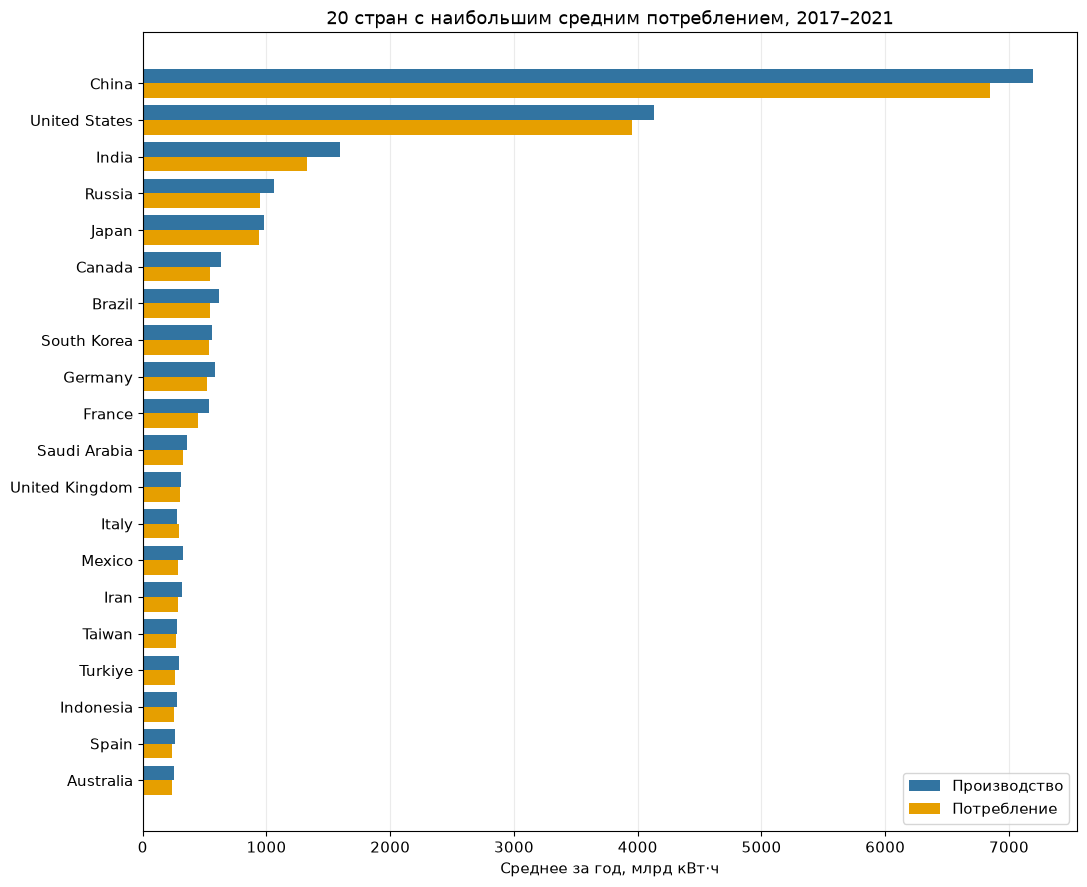

In [15]:
chart_idx = np.flatnonzero(np.isfinite(mean_consumption))
chart_idx = chart_idx[np.argsort(mean_consumption[chart_idx])[-20:]]
positions = np.arange(chart_idx.size)
fig, ax = plt.subplots(figsize=(11, 9))
ax.barh(positions + 0.2, mean_generation[chart_idx], height=0.4, label='Производство', color='#3274A1')
ax.barh(positions - 0.2, mean_consumption[chart_idx], height=0.4, label='Потребление', color='#E69F00')
ax.set_yticks(positions, countries[chart_idx])
ax.set_xlabel('Среднее за год, млрд кВт·ч')
ax.set_title('20 стран с наибольшим средним потреблением, 2017–2021')
ax.legend()
ax.grid(axis='x', alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

### 3.1. Суммарное потребление за каждый год
Суммирование по странам выполняется по `axis=0`. Суммы рассчитаны по известным значениям, без восстановления пропусков.


In [16]:
annual_consumption = np.nansum(consumption, axis=0)
for year, value in zip(years, annual_consumption):
    print(f'{year}: {value:.6f} млрд кВт·ч')

1992: 10569.016201 млрд кВт·ч
1993: 10854.562919 млрд кВт·ч
1994: 11104.653834 млрд кВт·ч
1995: 11476.479041 млрд кВт·ч
1996: 11805.865473 млрд кВт·ч
1997: 12122.033114 млрд кВт·ч
1998: 12419.808873 млрд кВт·ч
1999: 12685.754131 млрд кВт·ч
2000: 13230.249502 млрд кВт·ч
2001: 13486.489704 млрд кВт·ч
2002: 13938.778793 млрд кВт·ч
2003: 14455.562329 млрд кВт·ч
2004: 15128.097979 млрд кВт·ч
2005: 15725.982376 млрд кВт·ч
2006: 16438.213771 млрд кВт·ч
2007: 17205.119808 млрд кВт·ч
2008: 17477.471007 млрд кВт·ч
2009: 17435.687358 млрд кВт·ч
2010: 18748.160724 млрд кВт·ч
2011: 19438.823496 млрд кВт·ч
2012: 19918.254954 млрд кВт·ч
2013: 20573.096414 млрд кВт·ч
2014: 20981.239762 млрд кВт·ч
2015: 21400.017770 млрд кВт·ч
2016: 22022.686879 млрд кВт·ч
2017: 22716.206102 млрд кВт·ч
2018: 23530.920048 млрд кВт·ч
2019: 23915.656498 млрд кВт·ч
2020: 23959.680109 млрд кВт·ч
2021: 25336.707010 млрд кВт·ч


Динамика суммарного потребления по всем странам за 1992–2021 годы.

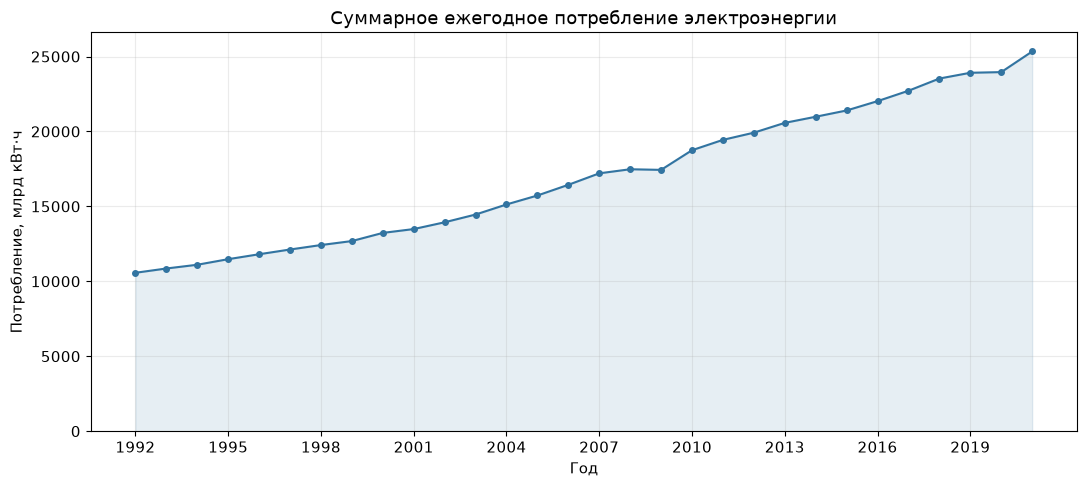

In [17]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(years, annual_consumption, marker='o', markersize=4, color='#3274A1')
ax.fill_between(years, annual_consumption, alpha=0.12, color='#3274A1')
ax.set(xlabel='Год', ylabel='Потребление, млрд кВт·ч', title='Суммарное ежегодное потребление электроэнергии')
ax.set_xticks(years[::3])
ax.set_ylim(bottom=0)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

### 3.2. Максимальное производство одной страны за один год

In [8]:
max_generation = np.nanmax(generation)
row, col = np.unravel_index(np.nanargmax(generation), generation.shape)
print(f'{countries[row]}, {years[col]} год: {max_generation:.6f} млрд кВт·ч')

China, 2021 год: 8151.518231 млрд кВт·ч


### 3.3. Страны со средним производством более 500 млрд кВт·ч за последние 5 лет

In [18]:
mask = mean_generation > 500
for country, value in zip(countries[mask], mean_generation[mask]):
    print(f'{country}: {value:.6f}')

Russia: 1059.992996
France: 533.218951
Germany: 581.558404
China: 7190.022571
India: 1595.249269
Japan: 983.880140
South Korea: 558.355090
Canada: 631.606399
United States: 4130.269086
Brazil: 614.184862


Страны расположены по среднему производству; пунктир показывает порог 500 млрд кВт·ч.

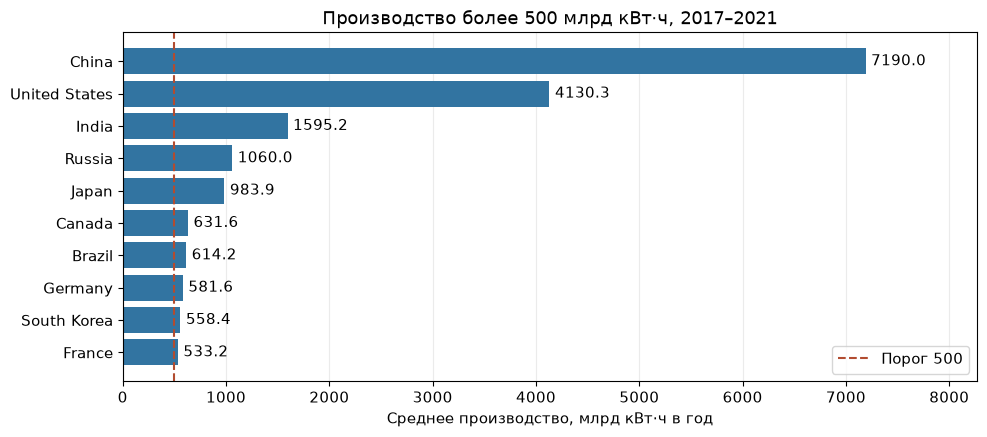

In [19]:
chart_idx = np.flatnonzero(mean_generation > 500)
chart_idx = chart_idx[np.argsort(mean_generation[chart_idx])]
fig, ax = plt.subplots(figsize=(10, max(4, chart_idx.size * 0.45)))
bars = ax.barh(countries[chart_idx], mean_generation[chart_idx], color='#3274A1')
ax.bar_label(bars, fmt='%.1f', padding=4)
ax.axvline(500, color='#B24C30', linestyle='--', label='Порог 500')
ax.set(xlabel='Среднее производство, млрд кВт·ч в год', title='Производство более 500 млрд кВт·ч, 2017–2021')
ax.margins(x=0.15)
ax.legend()
ax.grid(axis='x', alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

### 3.4. Верхние 10% стран по среднему потреблению за последние 5 лет
Находим квантиль уровня 0,9 и выбираем страны выше этого порога. Число стран целое, поэтому доля может немного отличаться от 10%.


In [20]:
threshold = np.nanquantile(mean_consumption, 0.9)
top_indices = np.flatnonzero(mean_consumption > threshold)
top_indices = top_indices[np.argsort(mean_consumption[top_indices])[::-1]]
print(f'Квантиль 0,9: {threshold:.6f} млрд кВт·ч')
print(f'Выбрано {top_indices.size} из {countries.size} стран ({100 * top_indices.size / countries.size:.2f}%)')
for i in top_indices:
    print(f'{countries[i]}: {mean_consumption[i]:.6f}')

Квантиль 0,9: 198.310526 млрд кВт·ч
Выбрано 22 из 217 стран (10.14%)
China: 6846.206993
United States: 3957.497224
India: 1330.936242
Russia: 946.678796
Japan: 940.321860
Canada: 547.319651
Brazil: 539.933482
South Korea: 539.511605
Germany: 520.234640
France: 445.223264
Saudi Arabia: 324.517126
United Kingdom: 303.543997
Italy: 296.443217
Mexico: 285.825534
Iran: 282.508003
Taiwan: 265.071970
Turkiye: 263.490688
Indonesia: 256.329860
Spain: 240.371533
Australia: 238.597478
Vietnam: 206.115838
South Africa: 200.649088


Показаны все страны выше 90-го процентиля. Пунктирная линия отмечает рассчитанный порог.

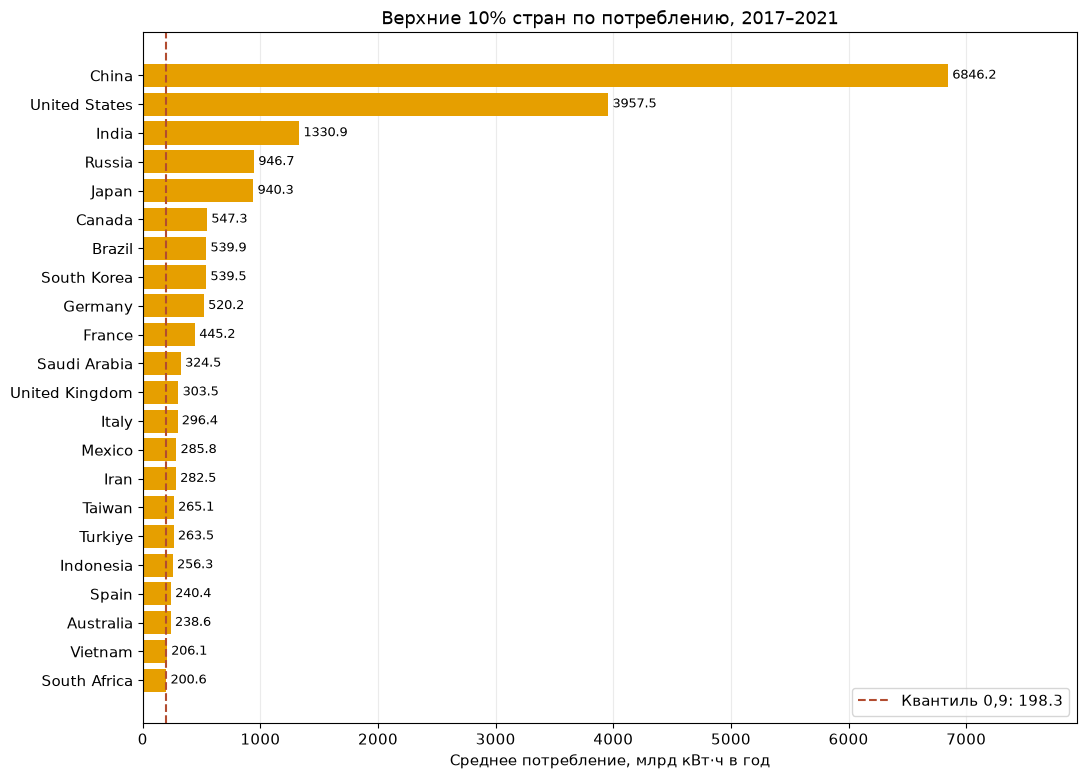

In [21]:
chart_idx = top_indices[::-1]
fig, ax = plt.subplots(figsize=(11, max(6, chart_idx.size * 0.36)))
bars = ax.barh(countries[chart_idx], mean_consumption[chart_idx], color='#E69F00')
ax.bar_label(bars, fmt='%.1f', padding=3, fontsize=9)
ax.axvline(threshold, color='#B24C30', linestyle='--', label=f'Квантиль 0,9: {threshold:.1f}')
ax.set(xlabel='Среднее потребление, млрд кВт·ч в год', title='Верхние 10% стран по потреблению, 2017–2021')
ax.margins(x=0.16)
ax.legend(loc='lower right')
ax.grid(axis='x', alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

### 3.5. Рост производства более чем в 10 раз между 1992 и 2021 годами
Отношение рассчитываем только при известных значениях обоих лет и положительном исходном производстве: при нулевой базе кратность роста не определена.


In [13]:
start = generation[:, np.flatnonzero(years == 1992)[0]]
end = generation[:, np.flatnonzero(years == 2021)[0]]
valid = np.isfinite(start) & np.isfinite(end) & (start > 0)
growth = np.divide(end, start, out=np.full(start.shape, np.nan), where=valid)
mask = growth > 10
for country, value in zip(countries[mask], growth[mask]):
    print(f'{country}: в {value:.6f} раза')

Angola: в 12.805450 раза
Benin: в 10.482490 раза
Equatorial Guinea: в 78.784698 раза
Ethiopia: в 12.021418 раза
Mali: в 12.502659 раза
Mauritania: в 13.495361 раза
Mozambique: в 48.793492 раза
Sudan: в 10.437374 раза
Cambodia: в 52.374894 раза
China: в 11.384166 раза
Laos: в 44.510932 раза
Maldives: в 23.642453 раза
Vietnam: в 25.850299 раза
Turks and Caicos Islands: в 10.482308 раза


Диаграмма показывает кратность роста для всех стран, удовлетворяющих условию. Пунктир — рост в 10 раз.

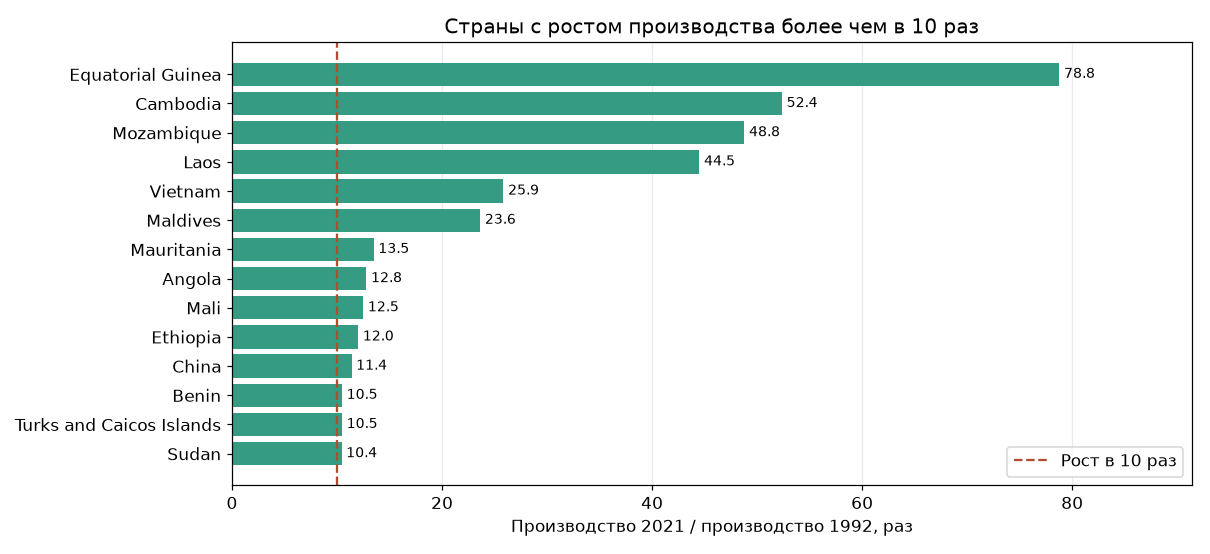

In [14]:
chart_idx = np.flatnonzero(growth > 10)
chart_idx = chart_idx[np.argsort(growth[chart_idx])]
fig, ax = plt.subplots(figsize=(11, max(5, chart_idx.size * 0.36)))
bars = ax.barh(countries[chart_idx], growth[chart_idx], color='#369B83')
ax.bar_label(bars, fmt='%.1f', padding=3, fontsize=9)
ax.axvline(10, color='#B24C30', linestyle='--', label='Рост в 10 раз')
ax.set(xlabel='Производство 2021 / производство 1992, раз', title='Страны с ростом производства более чем в 10 раз')
ax.margins(x=0.16)
ax.legend(loc='lower right')
ax.grid(axis='x', alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

### 3.6. Суммарное потребление более 100 млрд кВт·ч и производство меньше потребления
Сравниваем суммы по всем годам для каждой страны (`axis=1`), пропуски игнорируем. Чтобы не считать полное отсутствие наблюдений нулевым производством, требуем хотя бы одно известное значение в каждом ряду.


In [15]:
total_generation = np.nansum(generation, axis=1)
total_consumption = np.nansum(consumption, axis=1)
has_data = np.any(np.isfinite(generation), axis=1) & np.any(np.isfinite(consumption), axis=1)
mask = has_data & (total_consumption > 100) & (total_generation < total_consumption)
print(f'{"Страна":35} {"Производство":>15} {"Потребление":>15}')
for i in np.flatnonzero(mask):
    print(f'{countries[i]:35} {total_generation[i]:15.6f} {total_consumption[i]:15.6f}')

Страна                                 Производство     Потребление
Zimbabwe                                 238.184443      260.622536
Belarus                                  895.457144      922.326227
Moldova                                  180.223030      202.823030
Belgium                                 2342.357957     2395.907016
Croatia                                  342.391575      418.565217
Finland                                 2069.424885     2356.636611
Hungary                                  981.684218     1066.959623
Italy                                   7879.030316     8576.574545
Latvia                                   146.656834      179.287871
Luxembourg                                38.265581      177.538361
Netherlands                             2896.512827     3106.405315
North Macedonia                          177.760453      186.883806
Hong Kong                                998.423001     1152.851864


Для всех отобранных стран сравним суммарное производство и потребление за 1992–2021 годы. Страны отсортированы по разности «потребление − производство». Список разбит на группы до 20 стран, чтобы подписи оставались читаемыми. Разность рассчитана по имеющимся наблюдениям и не является оценкой импорта.

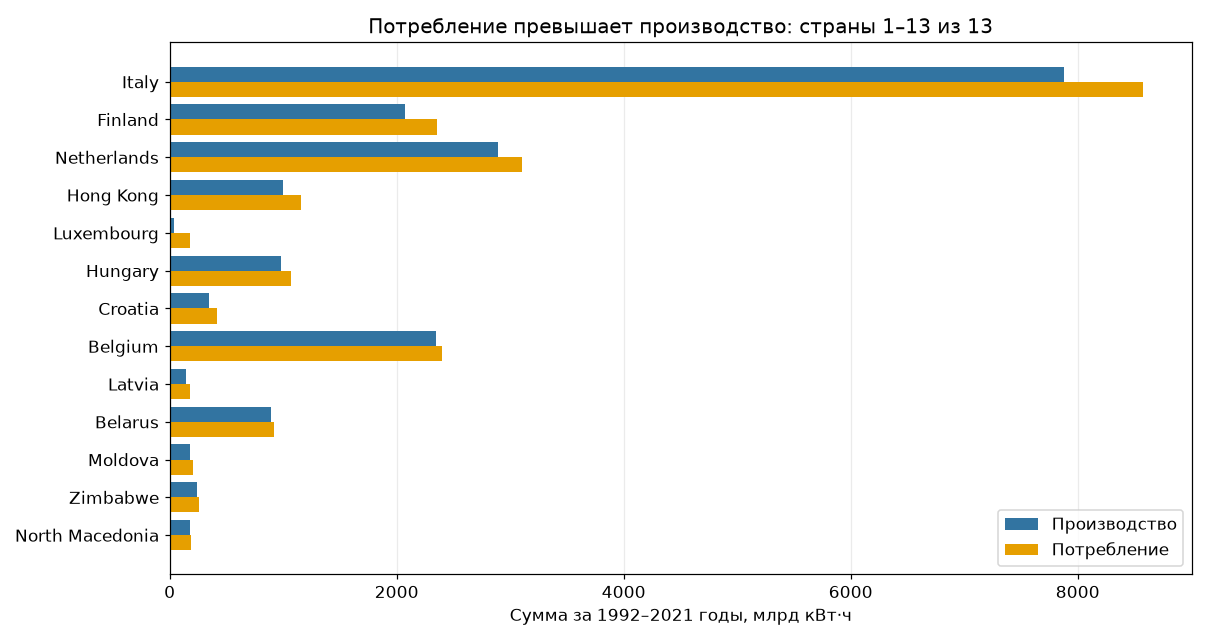

In [16]:
chart_idx = np.flatnonzero(has_data & (total_consumption > 100) & (total_generation < total_consumption))
chart_gap = total_consumption - total_generation
chart_idx = chart_idx[np.argsort(chart_gap[chart_idx])[::-1]]
for offset in range(0, chart_idx.size, 20):
    group = chart_idx[offset:offset + 20][::-1]
    positions = np.arange(group.size)
    fig, ax = plt.subplots(figsize=(11, max(5, group.size * 0.45)))
    ax.barh(positions + 0.2, total_generation[group], height=0.4, label='Производство', color='#3274A1')
    ax.barh(positions - 0.2, total_consumption[group], height=0.4, label='Потребление', color='#E69F00')
    ax.set_yticks(positions, countries[group])
    ax.set_xlabel('Сумма за 1992–2021 годы, млрд кВт·ч')
    ax.set_title(f'Потребление превышает производство: страны {offset + 1}–{offset + group.size} из {chart_idx.size}')
    ax.legend()
    ax.grid(axis='x', alpha=0.25)
    ax.set_axisbelow(True)
    fig.tight_layout()
    plt.show()

### 3.7. Страна с наибольшим потреблением в 2020 году

In [22]:
col2020 = np.flatnonzero(years == 2020)[0]
leader = np.nanargmax(consumption[:, col2020])
print(f'{countries[leader]}: {consumption[leader, col2020]:.6f} млрд кВт·ч')

China: 7115.077185 млрд кВт·ч


## Задача 2. Зависимость прибыли от скидки
Исходные данные разделены точкой с запятой, заголовка нет. Первый столбец — скидка в процентах (например, `6` означает 6%), второй — прибыль в условных единицах.


In [18]:
data = np.genfromtxt(StringIO(CSV_DATA['data2.csv']), delimiter=';')
x, y = data[:, 0], data[:, 1]
order = np.argsort(x)
x, y = x[order], y[order]
print('Скидки:', x)
print('Прибыль:', y)

Скидки: [0.  0.2 0.4 0.6 0.8 1.  1.2 1.4 1.6 1.8 2.  2.2 2.4 2.6 2.8 3.  3.2 3.4 3.6 3.8 4.  4.2 4.4 4.6 4.8 5. ]
Прибыль: [-7.697966 -6.572665 -5.370468 -3.158585 -1.482707 -0.123844  2.403896  4.146833  6.327902  8.822915
 10.885428 13.315577 15.47213  17.267434 18.818431 20.626338 23.040068 23.920533 25.322169 26.522987
 26.76261  27.658966 27.359734 27.37007  26.152154 25.239204]


### 1–3. Построение полинома второй степени
Берём три наблюдения около начала, середины и конца диапазона. Для каждой выбранной точки составляем уравнение
$$a_2x_i^2+a_1x_i+a_0=y_i.$$
Матрица системы содержит столбцы $x^2,x,1$. Коэффициенты находим через `scipy.linalg.solve`, затем вычисляем значения во всех исходных точках. Это интерполяция по выбранным точкам, а не метод наименьших квадратов по всему набору.


In [19]:
idx2 = np.rint(np.linspace(0, x.size - 1, 3)).astype(int)
A2 = np.vander(x[idx2], N=3)
b2 = y[idx2]
coef2 = solve(A2, b2)
y2 = np.polyval(coef2, x)
print('Выбранные точки (скидка, прибыль):\n', np.column_stack((x[idx2], b2)))
print('Матрица A2:\n', A2)
print('Правая часть b2:', b2)
print('Коэффициенты [a2, a1, a0]:', coef2)
print('Значения полинома:', y2)
assert np.allclose(A2 @ coef2, b2)

Выбранные точки (скидка, прибыль):
 [[ 0.       -7.697966]
 [ 2.4      15.47213 ]
 [ 5.       25.239204]]
Матрица A2:
 [[ 0.    0.    1.  ]
 [ 5.76  2.4   1.  ]
 [25.    5.    1.  ]]
Правая часть b2: [-7.697966 15.47213  25.239204]
Коэффициенты [a2, a1, a0]: [-1.179528 12.485074 -7.697966]
Значения полинома: [-7.697966 -5.248132 -2.892661 -0.631552  1.535195  3.60758   5.585602  7.469263  9.258561 10.953496
 12.55407  14.060281 15.47213  16.789617 18.012742 19.141504 20.175904 21.115942 21.961617 22.712931
 23.369882 23.932471 24.400698 24.774562 25.054064 25.239204]


### 4–5. Графики и квадратичное отклонение для второй степени
$$RSS=\sum_{i=1}^{n}(y_i-f(x_i))^2.$$

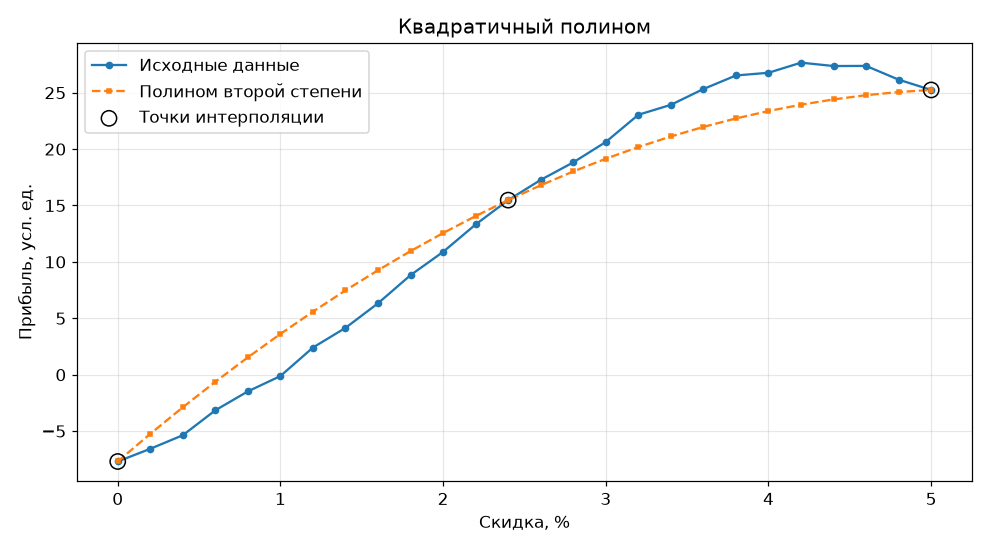

RSS для второй степени: 161.996858129


In [20]:
rss2 = np.sum((y - y2) ** 2)
plt.figure()
plt.plot(x, y, 'o-', label='Исходные данные', markersize=4)
plt.plot(x, y2, 's--', label='Полином второй степени', markersize=3)
plt.scatter(x[idx2], y[idx2], s=100, facecolors='none', edgecolors='black', label='Точки интерполяции', zorder=3)
plt.xlabel('Скидка, %')
plt.ylabel('Прибыль, усл. ед.')
plt.title('Квадратичный полином')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
print(f'RSS для второй степени: {rss2:.9f}')

### 6. Повторение шагов 1–5 для полинома третьей степени
Выбираем четыре примерно равномерно расположенные точки. Система состоит из уравнений
$$a_3x_i^3+a_2x_i^2+a_1x_i+a_0=y_i.$$


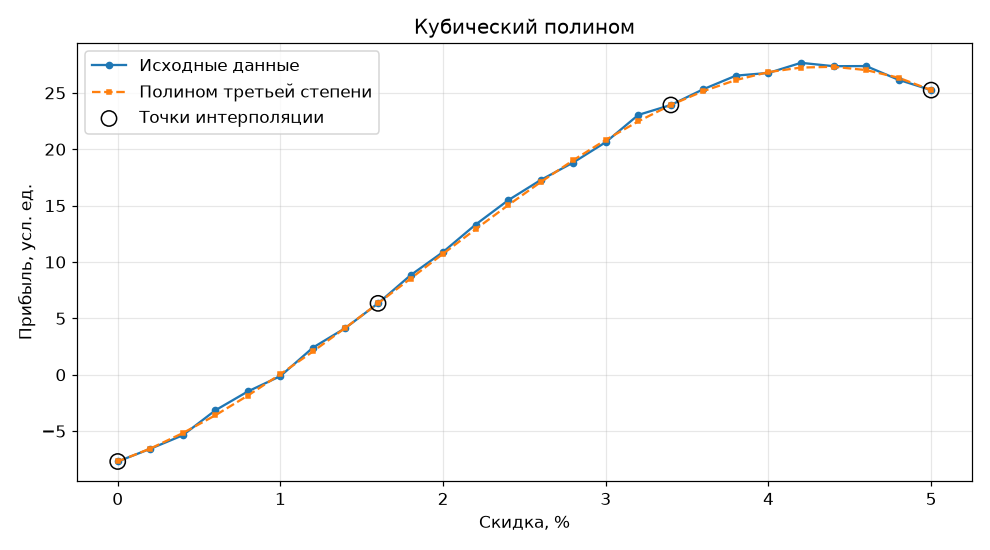

Выбранные точки (скидка, прибыль):
 [[ 0.       -7.697966]
 [ 1.6       6.327902]
 [ 3.4      23.920533]
 [ 5.       25.239204]]
Матрица A3:
 [[  0.      0.      0.      1.   ]
 [  4.096   2.56    1.6     1.   ]
 [ 39.304  11.56    3.4     1.   ]
 [125.     25.      5.      1.   ]]
Правая часть b3: [-7.697966  6.327902 23.920533 25.239204]
Коэффициенты [a3, a2, a1, a0]: [-0.585708  3.224866  5.105793 -7.697966]
Значения полинома: [-7.697966 -6.552498 -5.177155 -3.600051 -1.849299  0.046986  2.060691  4.163701  6.327902  8.525182
 10.727425 12.906517 15.034345 17.082795 19.023753 20.829104 22.470735 23.920533 25.150382 26.132168
 26.837779 27.2391   27.308017 27.016416 26.336183 25.239204]
RSS для третьей степени: 1.954214546


In [21]:
idx3 = np.rint(np.linspace(0, x.size - 1, 4)).astype(int)
A3 = np.vander(x[idx3], N=4)
b3 = y[idx3]
coef3 = solve(A3, b3)
y3 = np.polyval(coef3, x)
rss3 = np.sum((y - y3) ** 2)
print('Выбранные точки (скидка, прибыль):\n', np.column_stack((x[idx3], b3)))
print('Матрица A3:\n', A3)
print('Правая часть b3:', b3)
print('Коэффициенты [a3, a2, a1, a0]:', coef3)
print('Значения полинома:', y3)
assert np.allclose(A3 @ coef3, b3)

plt.figure()
plt.plot(x, y, 'o-', label='Исходные данные', markersize=4)
plt.plot(x, y3, 's--', label='Полином третьей степени', markersize=3)
plt.scatter(x[idx3], y[idx3], s=100, facecolors='none', edgecolors='black', label='Точки интерполяции', zorder=3)
plt.xlabel('Скидка, %')
plt.ylabel('Прибыль, усл. ед.')
plt.title('Кубический полином')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
print(f'RSS для третьей степени: {rss3:.9f}')

### 8. Выбор лучшего варианта и прогноз прибыли
Сравниваем RSS на **всех** исходных наблюдениях и выбираем полином с меньшим отклонением.


In [22]:
best_degree, best_coef, best_rss = (2, coef2, rss2) if rss2 <= rss3 else (3, coef3, rss3)
discounts = np.array([6.0, 8.0])
predictions = np.polyval(best_coef, discounts)
print(f'RSS второй степени: {rss2:.9f}')
print(f'RSS третьей степени: {rss3:.9f}')
print(f'Лучший вариант: степень {best_degree}, RSS = {best_rss:.9f}')
for discount, profit in zip(discounts, predictions):
    print(f'Ожидаемая прибыль при скидке {discount:g}%: {profit:.6f} усл. ед.')

RSS второй степени: 161.996858129
RSS третьей степени: 1.954214546
Лучший вариант: степень 3, RSS = 1.954214546
Ожидаемая прибыль при скидке 6%: 12.519133 усл. ед.
Ожидаемая прибыль при скидке 8%: -60.342480 усл. ед.


## Вывод
С помощью NumPy загружены и обработаны данные об электроэнергии: рассчитаны средние значения, суммы, максимум, квантиль и списки стран по заданным условиям. Пропуски учтены явно.

Для зависимости прибыли от скидки построены интерполяционные полиномы второй и третьей степени, решены соответствующие СЛУ, построены графики и рассчитаны RSS. Лучший из двух вариантов и значения при скидках 6% и 8% приведены выше. Эти скидки находятся за пределами исходного диапазона 0–5%, поэтому полученные значения являются экстраполяцией модели.
